# Учебный проект: Исследование стартапов

Автор: Минько Никита

Дата: 2026-09-02

Финансовая компания, работающая с венчурными инвестициями, хочет понять закономерности финансирования стартапов и оценить перспективы выхода на рынок с покупкой и развитием компаний. Для этого необходимо провести исследование на исторических данных. Мы поработаем с информацией о компаниях, объёмах и типах привлечённых инвестиций, а также с дополнительной статистикой по возвратам средств.

**Цель проекта** — подготовить датасет к работе, исследовать динамику и структуру финансирования стартапов и ответить на вопросы, важные для оценки инвестиционных стратегий.

В рамках проекта нам предстоит:
- Провести предобработку данных, убрать дубликаты и пропуски, проверить корректность числовых и временных значений.
- Выделить группы компаний по срокам финансирования и сравнить их по количеству и объёму инвестиций.
- Классифицировать сегменты рынка на массовые, средние и нишевые и учесть это в дальнейшем анализе.
- Определить типичные и аномальные значения объёмов финансирования, исключить выбросы и ограничить период исследования.
- Сравнить популярность и объёмы разных типов финансирования.
- Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка.
- Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость.
- Подвести итоговые выводы и дать рекомендации, куда и каким образом было бы целесообразно инвестировать, если бы на дворе был 2015 год.

### 0.1. Предварительное описание данных:

#### Таблица `cb_investments`
Содержит информацию о компаниях и состоявшемся финансировании:
- `name` — название компании;
- `homepage_url` — ссылка на сайт компании;
- `category_list` — категории, в которых работает компания. Указываются через |;
- `market` — основной рынок или отрасль компании;
- `funding_total_usd` — общий объём привлечённых инвестиций в долларах США;
- `status` — текущий статус компании, например, operating, closed и так далее;
- `country_code` — код страны, например USA;
- `state_code` — код штата или региона, например CA;
- `region` — регион, например SF Bay Area;
- `city` — город, в котором расположена компания;
- `funding_rounds` — общее число раундов финансирования;
- `participants` — число участников в раундах финансирования;
- `founded_at` — дата основания компании;
- `founded_month` — месяц основания в формате YYYY-MM;
- `founded_quarter` — квартал основания в формате YYYY-QN;
- `founded_year` — год основания;
- `first_funding_at` — дата первого финансирования;
- `mid_funding_at` — дата среднего по времени раунда финансирования;
- `last_funding_at` — дата последнего финансирования;
- `seed` — сумма инвестиций на посевной стадии;
- `venture` — сумма венчурных инвестиций;
- `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг;
- `undisclosed` — сумма финансирования нераскрытого типа;
- `convertible_note` — сумма инвестиций через конвертируемые займы;
- `debt_financing` — сумма долгового финансирования;
- `angel` — сумма инвестиций от бизнес-ангелов;
- `grant` — сумма полученных грантов;
- `private_equity` — сумма инвестиций в виде прямых (частных) вложений;
- `post_ipo_equity` — сумма финансирования после IPO;
- `post_ipo_debt` — сумма долгового финансирования после IPO;
- `secondary_market` — сумма сделок на вторичном рынке;
- `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг;
- `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

#### Таблица `cb_returns`
Содержит информацию об объёмах возвратов по годам и типам финансирования в миллионах долларов:
- `year` — год возврата средств;
- `seed` — сумма возвратов от посевных инвестиций;
- `venture` — сумма возвратов от венчурных инвестиций;
- `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу;
- `undisclosed` — сумма возвратов нераскрытого типа;
- `convertible_note` — сумма возвратов через конвертируемые займы;
- `debt_financing` — сумма возвратов от долгового финансирования;
- `angel` — сумма возвратов бизнес-ангелам;
- `grant` — сумма возвратов по грантам;
- `private_equity` — сумма возвратов прямых (частных) вложений;
- `post_ipo_equity` — сумма возвратов от IPO;
- `post_ipo_debt` — сумма возвратов от долгового IPO;
- `secondary_market` — сумма возвратов от сделок на вторичном рынке;
- `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

<a id="Содержание"></a>
### 0.2. Содержание

1. [Знакомство с данными: загрузка и предобработка](#Знакомство-с-данными)
    - [Вывод общей информации](#Вывод-общей-информации)
        - [Знакомство с `cb_investments`](#Знакомство-с-cb_investments)
        - [Знакомство с `cb_returns`](#Знакомство-с-cb_returns)
    - [Предобработка данных](#Предобработка-данных)
        - [Названия столбцов](#Названия-столбцов)
        - [Типы данных](#Типы-данных)
        - [Структура таблицы `cb_returns`](#Структура-таблицы-cb_returns)
        - [Пропуски](#Пропуски)
        - [Дубликаты](#Дубликаты)
    - [Выводы после знакомства с данными и их предобработки](#Выводы-после-знакомства-и-предобработки)
2. [Инжиниринг признаков](#Инжиниринг-признаков)
    - [Группы по срокам финансирования](#Группы-по-срокам-финансирования)
    - [Выделение средних и нишевых сегментов рынка](#Выделение-средних-и-нишевых-сегментов-рынка)
    - [Результат инжиниринга признаков](#Результат-инжиниринга-признаков)
3. [Работа с выбросами и анализ](#Работа-с-выбросами-и-анализ)
    - [Анализируем и помечаем выбросы в каждом из сегментов](#Анализируем-и-помечаем-выбросы-в-каждом-из-сегментов)
    - [Определяем границы рассматриваемого периода, отбрасываем аномалии](#Определяем-границы-рассматриваемого-периода)
    - [Анализ типов финансирования по объёму и популярности](#Анализ-типов-финансирования-по-объёму-и-популярности)
    - [Результат работы с выбросами и анализа](#Результат-работы-с-выбросами-и-анализа)
4. [Анализ динамики](#Анализ-динамики)
    - [Динамика предоставления финансирования по годам](#Динамика-предоставления-финансирования-по-годам)
    - [Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов](#Динамика-размера-общего-финансирования-по-массовым-сегментам)
    - [Годовая динамика доли возвращённых средств по типам финансирования](#Годовая-динамика-доли-возвращённых-средств)
    - [Результат анализа динамики](#Результат-анализа-динамики)
5. [Итоговый вывод и рекомендации](#Итоговый-вывод-и-рекомендации)
    - [Обзор проделанной работы и выводы](#Обзор-проделанной-работы-и-выводы)
    - [Рекомендации инвесторам](#Рекомендации-инвесторам)

Приступим к загрузке данных и знакомству с ними.

<a id="Знакомство-с-данными"></a>
## 1. Знакомство с данными: загрузка и предобработка

<a id="Вывод-общей-информации"></a>
### 1.1. Вывод общей информации

Для начала импортируем необходимые нам библиотеки. Будем использовать `pandas` и библиотеки визуализации данных `matplotlib` и `seaborn`.

In [1]:
# Импортируем необходимые библиотеки:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Выгрузим наши датасеты `cb_investments` и `cb_returns`. Сохраним их в соответствующие датафреймы.

In [2]:
# Выгружаем наши датасеты в датафреймы:
cb_investments = pd.read_csv("https://xxxxxxxxx/xxxxxx/cb_investments.zip",
                             sep = ';',
                             low_memory = False)

cb_returns = pd.read_csv('https://xxxxxxxxx/xxxxxx/cb_returns.csv')

[Вернуться к содержанию](#Содержание)

<a id="Знакомство-с-cb_investments"></a>
#### 1.1.1. Знакомство с `cb_investments`

Чтобы убедиться, что у нас получилось выгрузить датасет и сформировать датафрейм, выведем первые 5 строк. Также посмотрим общую сводку о структуре датафрейма, используя метод `info()`.

In [3]:
# Выведем первые 5 строк:
cb_investments.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Выведем краткую сводку по данному датафрейму:
cb_investments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

По полученным данным можем сформировать следующий вывод:

Датасет `cb_investments` содержит 40 столбцов и 54294 строки, в которых представлена информация о компаниях и состоявшемся финансировании. В названиях некоторых столбцов (` market ` и ` funding_total_usd `) присутствуют лишние пробелы, которые потребуется устранить на этапе предобработки. Содержимое столбцов в целом соответствует описанию из ТЗ, однако во многих из них наблюдается значительное количество пропущенных значений.

Изучим типы данных и их корректность:

- **Строковые данные (str или object).** Шестнадцать столбцов имеют тип данных `object`:
    - `name` содержит название компании. Соответствует выбранному типу данных, однако имеет пропуски;
    - `homepage_url` содержит ссылку на сайт компании. Тип данных оптимален;
    - `category_list` содержит список категорий, разделенных символом `|`. Строковый тип данных здесь корректен;
    - `market` содержит информацию об основном рынке или отрасли. Тип данных оптимален;
    - `funding_total_usd` содержит общий объём привлечённых инвестиций в долларах США. По описанию данных это числовой показатель, но текущий тип данных - строковый. Это указывает на наличие нечисловых символов, скрытых пропусков. Потребуется очистка данных и приведение к числовому типу;
    - `status` содержит текущий статус компании (например, operating, closed), тип данных оптимален;
    - `country_code`, `state_code`, `region`, `city` содержат географические маркеры (коды стран, штатов, городов). Строковый тип данных для них является верным;
    - `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at` содержат даты событий. Тип данных `object` для них не подходит, поэтому в дальнейшем их необходимо привести к типу `datetime64` для корректной работы с данными времени;
    - `founded_month` и `founded_quarter` содержат строковые данные периодов основания в форматах `YYYY-MM` и `YYYY-QN` соответственно. Использование типа `object` для них допустимо.
- **Числовые значения с плавающей запятой (float64).** Двадцать четыре столбца имеют тип данных `float64`:
    - `funding_rounds` отображает общее число раундов финансирования. По логике это целое число (`int`), но из-за наличия пропусков `pandas` автоматически привел столбец к типу `float64`. Можно было бы привести к nullable-типу `Int`, который сохранит пропуски (он требует больше памяти, чем `int`). Если мы в дальнейшем решим удалить пропуски, то приведем к нужному нам `int`. Однако стоит отметить, что даже выбранный уже `float64` не повлияет на наши будущие вычисления (кроме как ухудшит визуальное восприятие);
    - `participants` содержит число участников в раундах финансирования. Аналогично предыдущему пункту, содержит целые числа, которые из-за пропусков записаны как `float64`;
    - `founded_year` содержит год основания компании. Год является целым числом, но имеет формат `float64` из-за пропущенных значений (по аналогии с `funding_rounds`);
    - Стадии финансирования (`seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market`, `product_crowdfunding`) и раунды от `round_A` до `round_H` содержат суммы инвестиций в долларах. Для отображения денежных сумм тип данных `float64` является оптимальным. Стоит отметить, что в этих столбцах зафиксировано одинаковое количество заполненных строк (49438), что может указывать на единый характер пропусков в финансовых блоках.

Заметим, что в некоторых столбцах встречаются пропуски. Посчитаем их абсолютное и относительное количество:

In [5]:
# Считаем абсолютное значение (их сумму по столбцам):
missing_sum_cb_investments = cb_investments.isna().sum()

# Считаем относительное значение (долю) и переводим в проценты:
missing_share_cb_investments = cb_investments.isna().mean() * 100

# Округлим относительное значение:
missing_share_cb_investments = missing_share_cb_investments.round(2)

# Создадим датафрейм с пропусками для наглядности:
missing_cb_investments = pd.DataFrame({'Количество пропусков': missing_sum_cb_investments,
                                       'Доля пропусков в процентах': missing_share_cb_investments})

# Выведем датафрейм:
missing_cb_investments

,Количество пропусков,Доля пропусков в процентах
name,4857,8.95
homepage_url,8305,15.30
category_list,8817,16.24
market,8817,16.24
funding_total_usd,4856,8.94
status,6170,11.36
country_code,10129,18.66
state_code,24133,44.45
region,10129,18.66
city,10972,20.21


Наблюдаем пропуски во всех столбцах таблицы, которые можно разделить на группы:

- **Инвестиционные и финансовые показатели** (`funding_total_usd`, `funding_rounds`, `first_funding_at`, `last_funding_at`, а также все типы инвестиций от `seed` до `round_H`). Все эти 24 столбца имеют одинаковое число пропущенных значений. Каждый из них содержит 4856 пропусков (8,94% от данных в столбце). Это указывает на то, что пропуски в них взаимосвязаны (например, отсутствуют данные по финансированию для конкретных компаний целиком). Позже проверим, так ли это.
- **Основная информация о компаниях:**
    - `name` содержит 4857 пропусков (8,95% от данных в столбце);
    - `status` содержит 6170 пропусков (11,36% от данных в столбце);
    - `homepage_url` содержит 8305 пропусков (15,30% от данных в столбце);
    - `category_list` и `market` содержат по 8817 пропусков (16,24% от данных в столбце).
- **Географические данные:**
    - `country_code` и `region` содержат по 10129 пропусков (18,66% от данных в столбце);
    - `city` содержит 10972 пропуска (20,21% от данных в столбце);
    - `state_code` содержит большое количество пропусков — 24133 (44,45% от данных в столбце), что объясняется тем, что коды штатов актуальны преимущественно для компаний из США.
- **Временные маркеры и участники:**
    - `founded_at` и `founded_year` содержат по 15740 пропусков (28,99% от данных в столбце);
    - `founded_month` и `founded_quarter` содержат по 15812 пропусков (29,12% от данных в столбце);
    - `participants` содержит большое количество пропусков — 23821 (43,87% от данных в столбце);
    - `mid_funding_at` содержит наибольшее количество пропусков — 24006 (44,21% от данных в столбце).

Вернемся к этому на этапе предобработки.

[Вернуться к содержанию](#Содержание)

<a id="Знакомство-с-cb_returns"></a>
#### 1.1.2. Знакомство с `cb_returns`

Как и в случае с `cb_investments`, выведем первые 5 строк. Также посмотрим общую сводку о структуре датафрейма, используя метод `info()`.

In [6]:
# Выведем первые 5 строк:
cb_returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [7]:
# Выведем краткую сводку по данному датафрейму:
cb_returns.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


По полученным данным можем сформировать следующий вывод:

Датасет `cb_returns` содержит 14 столбцов и 15 строк, в которых представлена информация об объёмах возвратов по годам и типам финансирования в миллионах долларов. Все 15 строк заполнены, т.е. пропущенные значения в таблице отсутствуют. Данные полностью соответствуют описанию.

Изучим типы данных и их корректность:

- **Целочисленные значения (int64).** Один столбец содержит тип данных `int64`: `year` содержит год возврата средств. Так как год выражен целым числом и в столбце нет пропусков, выбранный тип данных является оптимальным. Для оптимизации памяти можно было бы понизить разрядность до `int16`, но в этом нет острой необходимости.
- **Числовые значения с плавающей запятой (float64).** Тринадцать столбцов имеют тип данных `float64`: столбцы, отображающие суммы возвратов средств по различным типам финансирования (`seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market`, `product_crowdfunding`), содержат финансовые показатели в миллионах долларов. Так как денежные суммы могут быть дробными, использование типа данных `float64` является полностью обоснованным и оптимальным.

[Вернуться к содержанию](#Содержание)

<a id="Предобработка-данных"></a>
### 1.2. Предобработка данных

В рамках предобработки данных будем двигаться по следующим шагам:
1. Устраним лишние пробелы в названиях столбцов, где они есть;
2. Преобразуем типы данных:
    - Уберем выделение разрядов в столбце `funding_total_usd` и приведем его к числовому типу;
    - Преобразуем столбцы, хранящие значения даты и времени, в специальный формат `datetime64`;
3. Изменим структуру таблицы `cb_returns`, установив столбец `year` в качестве индекса всего датасета;
4. Проведем работу с пропусками:
    - Заполним пропуски в строковых столбцах специальными заглушками там, где это необходимо;
    - Избавимся от строк, которые не несут полезной информации или содержат пропуски в ключевом показателе `funding_total_usd` и других столбцах, содержащих информацию о финансировании;
    - Заполним пропущенные значения в столбце `mid_funding_at`, рассчитав середину временного интервала между датами первого (`first_funding_at`) и последнего (`last_funding_at`) финансирования;
5. Обработаем текстовые значения, избавившись от неявных дубликатов. Также проверим данные на полные дубликаты и удалим их.

В конце оценим полноту очищенных данных: посчитаем долю удаленной информации, проанализируем оставшиеся пропуски в столбцах и сделаем предварительный вывод о достаточности данных для решения задач проекта.

[Вернуться к содержанию](#Содержание)

<a id="Названия-столбцов"></a>
#### 1.2.1. Названия столбцов

Выведем названия столбцов в наших датасетах:

In [8]:
# Выведем названия столбцов в cb_investments:
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [9]:
# Выведем названия столбцов в cb_returns:
cb_returns.columns

Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')

Видим, что все названия отражают содержимое и приведены к "питоновскому" стилю `snake case`. Однако два столбца в `cb_investments`, которые мы уже отметили на этапе знакомства с данными, - ` market ` и ` funding_total_usd ` имеют лишние пробелы до и после самого названия. Давайте уберем все лишние пробелы:

In [10]:
# Уберем пробелы из названий столбцов в cb_investments:
cb_investments.columns = cb_investments.columns.str.strip()

# Проверим теперь наши названия:
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', 'market', 'funding_total_usd',
       'status', 'country_code', 'state_code', 'region', 'city',
       'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

Получилось. Теперь все названия в обоих датафреймах соответсвуют установленному стилю.

P.s. также в данном случае, где всего два столбца нужно переименовать, можно было использовать метод `rename()`, однако наш аналитик поленился (но не поленился написать этот текст).

[Вернуться к содержанию](#Содержание)

<a id="Типы-данных"></a>
#### 1.2.2. Типы данных

На этапе знакомства с данными мы установили, что преобразований типов данных требуют столбцы:
1. `funding_total_usd` - из строкового в числовой;
2. `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at` - из строкового в специальный формат `datetime64`.

Приступим.

1. Значения в `funding_total_usd` представлены в виде `9,00,00,000`. Давайте уберем выделение разрядов в столбце и приведем его к числовому типу:

In [11]:
# Удалим запятые и приведем столбец к числовому типу.
# Добавим errors = 'coerce', чтобы он превратил возможные текстовые значения в пропуск:
cb_investments['funding_total_usd'] = pd.to_numeric(cb_investments['funding_total_usd'].str.replace(',', ''),
                                                    errors = 'coerce')

# Выведем результат:
print(f"Теперь тип данных в столбце funding_total_usd: {cb_investments['funding_total_usd'].dtype}")

Теперь тип данных в столбце funding_total_usd: float64


Давайте посчитаем сколько новых пропусков в `funding_total_usd` появилось:

In [12]:
# Посчитаем новое количество пропусков:
current_funding_missing = cb_investments['funding_total_usd'].isna().sum()

# Сохраним в переменную пропуски, которые мы считали на этапе знакомства с данными:
old_funding_missing = missing_sum_cb_investments[' funding_total_usd ']

# Найдем разницу между текущим количеством и сохраненным на этапе знакомства:
added_funding_missing = current_funding_missing - old_funding_missing

# Выведем результат:
print(f'В столбце funding_total_usd добавилось еще {added_funding_missing} пропусков')

В столбце funding_total_usd добавилось еще 8531 пропусков


Итак, получилось. Мы убрали в `funding_total_usd` выделение разрядов и привели данный столбец к числовому типу данных `float64`. В процессе у нас образовались новые пропуски (8531 ед.) из-за того, что в данном столбце ещё содержалась текстовая информация (например, `-`), которая собственно и была заменена на пропуск. 

2. Теперь преобразуем столбцы `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, хранящие значения даты и времени, в специальный формат `datetime64`:

In [13]:
# Для удобства сохраним названия столбцов в список:
date_columns = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

# Создадим цикл, который приведет к типу данных datetime64 каждый столбец из нашего списка:
for column in date_columns:
    cb_investments[column] = pd.to_datetime(cb_investments[column], format='%Y-%m-%d', errors = 'coerce')
    
    # Выведем наш результат:
    print(f"Теперь тип данных в столбце {column}: {cb_investments[column].dtype}")

Теперь тип данных в столбце founded_at: datetime64[ns]
Теперь тип данных в столбце first_funding_at: datetime64[ns]
Теперь тип данных в столбце mid_funding_at: datetime64[ns]
Теперь тип данных в столбце last_funding_at: datetime64[ns]


Итак, получилось. Мы поработали с некорректными типами данных и привели их в надлежащий вид:
1. В столбце `funding_total_usd` убрали выделение разрядов и привели сам столбец к числовому типу `float64`;
2. Преобразовали столбцы `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, хранящие значения даты и времени, в специальный формат `datetime64`.

[Вернуться к содержанию](#Содержание)

<a id="Структура-таблицы-cb_returns"></a>
#### 1.2.3. Структура таблицы `cb_returns`

В рамках проекта нам необходимо изменить структуру таблицы `cb_returns`, установив столбец `year` в качестве индекса всего датасета. Сделаем это:

In [14]:
# Установим индекс по столбцу с годом:
cb_returns = cb_returns.set_index('year')

# Выведем первые 5 строк таблицы для проверки:
cb_returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


Получилось. Теперь в датафрейме `cb_returns` индекс представлен в виде года.

[Вернуться к содержанию](#Содержание)

<a id="Пропуски"></a>
#### 1.2.4. Пропуски

В датасете `cb_returns` пропуски не были обнаружены, а вот в датасете `cb_investments` их было достаточное количество. Мы их разделили на группы:
- **Инвестиционные и финансовые показатели** (`funding_total_usd`, `funding_rounds`, `first_funding_at`, `last_funding_at`, а также все типы инвестиций от `seed` до `round_H`). Все эти 24 столбца имеют одинаковое число пропущенных значений (в `funding_total_usd` добавилось еще 8531 пропусков). Каждый из них содержит 4856 пропусков (8,94% от данных в столбце). Это указывает на то, что пропуски в них взаимосвязаны (например, отсутствуют данные по финансированию для конкретных компаний целиком).
- **Основная информация о компаниях:**
    - `name` содержит 4857 пропусков (8,95% от данных в столбце);
    - `status` содержит 6170 пропусков (11,36% от данных в столбце);
    - `homepage_url` содержит 8305 пропусков (15,30% от данных в столбце);
    - `category_list` и `market` содержат по 8817 пропусков (16,24% от данных в столбце).
- **Географические данные:**
    - `country_code` и `region` содержат по 10129 пропусков (18,66% от данных в столбце);
    - `city` содержит 10972 пропуска (20,21% от данных в столбце);
    - `state_code` содержит большое количество пропусков — 24133 (44,45% от данных в столбце).
- **Временные маркеры и участники:**
    - `founded_at` и `founded_year` содержат по 15740 пропусков (28,99% от данных в столбце);
    - `founded_month` и `founded_quarter` содержат по 15812 пропусков (29,12% от данных в столбце);
    - `participants` содержит большое количество пропусков — 23821 (43,87% от данных в столбце);
    - `mid_funding_at` содержит наибольшее количество пропусков — 24006 (44,21% от данных в столбце).
    
Эти пропуски можно объяснить так:
- технический сбой при выгрузке. Точно проследить это можно в пропусках в `name` и столбцах, отражающих финансирование;
- специфика сбора данных. Например, участники, указанные в `participants`, могут являться коммерческой тайной. Пропуски в `state_code` актуальны для всех стран, кроме США. Многую информацию о компаниях основатели могут не заполнить по каким-либо личным причинам (непример, не видят надобности в этом). Также, например, данные в столбце `mid_funding_at` невозможно рассчитать для компаний, у которых было всего 1–2 раунда инвестиций.

Итак, в рамках работы над пропусками в `cb_investments` мы:

1. Заполним пропуски в строковых столбцах специальными заглушками там, где это необходимо;

2. Избавимся от строк, которые не несут полезной информации или содержат пропуски в ключевом показателе `funding_total_usd` и других столбцах, содержащих информацию о финансировании;

3. Заполним пропущенные значения в столбце `mid_funding_at`, рассчитав середину временного интервала между датами первого (`first_funding_at`) и последнего (`last_funding_at`) финансирования.


Приступим.
1. В текстовых столбцах `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`, `city` следует заполнить пропуски заглушками. Столбец `name` мы оставим пока нетронутым. Пропуски в `founded_month` и `founded_quarter` мы заполним на основании `founded_at`.

Для начала заполняем заглушками:

In [15]:
# Сохраним в переменную список из нужных нам текстовых столбцов:
text_columns = ['homepage_url', 'category_list', 'market', 'status',
                'country_code', 'state_code', 'region', 'city']

# Заполним пропуски значением "не указано":
cb_investments[text_columns] = cb_investments[text_columns].fillna('не указано')

Готово. Теперь заполним пропуски в столбца`founded_month` и `founded_quarter`, которые содержат месяц и квартал основания стартапов, на основании `founded_at`, который содержит конкретную дату основания:

In [16]:
# Извлечем месяц в формате YYYY-MM:
month_extracted = cb_investments['founded_at'].dt.strftime('%Y-%m')
month_extracted = month_extracted.replace('NaT', None)

# Извлечем квартал в формате YYYY-QN и добавим 'Q' перед номером квартала для нашего формата:
quarter_extracted = cb_investments['founded_at'].dt.to_period('Q').astype(str).str.replace('-', '-Q')
quarter_extracted = quarter_extracted.replace('NaT', None)

# Заполним пропуски:
cb_investments['founded_month'] = cb_investments['founded_month'].fillna(month_extracted)
cb_investments['founded_quarter'] = cb_investments['founded_quarter'].fillna(quarter_extracted)

Готово. Двигаемся дальше.

2. Избавимся от строк, которые не несут полезной информации или содержат пропуски в ключевом показателе `funding_total_usd` и других столбцах, содержащих информацию о финансировании (`funding_rounds`, `first_funding_at`, `last_funding_at`, а также все типы инвестиций от `seed` до `round_H`). Предполагаем, что удалив пропуски в `funding_total_usd`, мы удалим все пропуски в других столбцах с информацией о финансировании, так как они связаны между собой. Позже проверим, верно ли наше предоположение, а сейчас удалим сами пропуски:

In [17]:
# Удаляем строки, где отсутствует ключевой показатель финансирования:
cb_investments = cb_investments.dropna(subset = ['funding_total_usd'])

Готово.

3. Теперь заполним пропущенные значения в столбце `mid_funding_at`, рассчитав середину временного интервала между датами первого (`first_funding_at`) и последнего (`last_funding_at`) финансирования:

In [18]:
# Заполним пропуски в first_funding_at, значениями из last_funding_at:
cb_investments['first_funding_at'] = cb_investments['first_funding_at'].fillna(cb_investments['last_funding_at'])

# Посчитаем среднюю дату:
mid_funding_calculated = cb_investments['first_funding_at'] + (cb_investments['last_funding_at'] - cb_investments['first_funding_at']) / 2

# Заполним пропуски:
cb_investments['mid_funding_at'] = cb_investments['mid_funding_at'].fillna(mid_funding_calculated)

Готово. Давайте теперь оценим ситуацию с пропусками:

In [19]:
# Считаем абсолютное значение (их сумму по столбцам):
new_missing_sum_cb_investments = cb_investments.isna().sum()

# Считаем относительное значение (долю) и переводим в проценты:
new_missing_share_cb_investments = cb_investments.isna().mean() * 100

# Округлим относительное значение:
new_missing_share_cb_investments = new_missing_share_cb_investments.round(2)

# Создадим датафрейм с пропусками для наглядности:
new_missing_cb_investments = pd.DataFrame({'Количество пропусков': new_missing_sum_cb_investments,
                                           'Доля пропусков в процентах': new_missing_share_cb_investments})

# Выведем датафрейм:
new_missing_cb_investments

,Количество пропусков,Доля пропусков в процентах
name,1,0.00
homepage_url,0,0.00
category_list,0,0.00
market,0,0.00
funding_total_usd,0,0.00
status,0,0.00
country_code,0,0.00
state_code,0,0.00
region,0,0.00
city,0,0.00


Видим, что наше предположения о связи пропусков в столбцах, содержащих информацию о финансировании (`funding_rounds`, `first_funding_at`, `last_funding_at`, а также все типы инвестиций от `seed` до `round_H`), и пропусков в столбце с ключевым показателем (`funding_total_usd`) было верным.

Также видна взаимосвязь этих столбцов с `name`. В самом начале мы отметили, что в `name` было 4 857 пропусков, а в финансовых показателях — 4 856. Это означает, что 4 856 строк были бесполезными (в них не было ни имени, ни информации о финансах), и мы их удалили. Но осталась одна уникальная строка компании, у которой есть данные о финансировании, но само название фирмы не указано. Так как мы уже заполнили текстовые столбцы заглушкой "не указано", этот пропуск можно закрыть точно так же:

In [20]:
# Заполним этот пропуск в name:
cb_investments['name'] = cb_investments['name'].fillna('не указано')

Отметим, что у нас остались пропуски:
- `participants` - 13576 пропусков (33,19%);
- `founded_at` - 8707 пропусков (21,28%);
- `founded_month`	- 8707 пропусков (21,28%);
- `founded_quarter`	- 8707 пропусков (21,28%);
- `founded_year` - 8706 пропусков (21,28%).

Их удаление приведет к искажению результатов будущего исследования, поэтому оставим их нетронутыми.

Таким образом, в рамках работы над пропусками мы:
1. Заполнили пропуски в текстовых столбцах `name`, `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`, `city` заглушкой `'не указано'`, а пропуски в столбца`founded_month` и `founded_quarter`, которые содержат месяц и квартал основания стартапов, - на основании `founded_at`, который содержит конкретную дату основания;
2. Удалили строки, которые не несут полезной информации или содержат пропуски в ключевом показателе `funding_total_usd` и других столбцах, содержащих информацию о финансировании;
3. Заполнили пропуски в `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков мы взяли приблизительно середину интервала между этими двумя датами.

[Вернуться к содержанию](#Содержание)

<a id="Дубликаты"></a>
#### 1.2.5. Дубликаты

Давайте поработаем с неявными дубликатами в текстовых столбцах `cb_investments`. В наших текстовых столбцах (`name`, `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`, `city`) уберем лишние пробелы, если они есть, в начале и конце строк, чтобы предотвратить возможное искажение результатов нашего исследования:

In [21]:
# Запишем в список наши текстовые столбцы:
new_text_columns = ['name', 'homepage_url', 'category_list', 'market', 'status', 'country_code', 'state_code', 'region', 'city']

# Создадим цикл, который очистит наши текстовые столбцы от пробелов:
for column in new_text_columns:
    # Посчитаем количество уникальных значений до чистки:
    old_unique = cb_investments[column].nunique()
    
    # Удалим пробелы по краям:
    cb_investments[column] = cb_investments[column].str.strip()
    
    # Посчитаем количество уникальных значений после чистки:
    new_unique = cb_investments[column].nunique()
    
    # Выведем результат:
    print(f'Количество уникальных значений в столбце {column} до чистки: {old_unique}')
    print(f'Количество уникальных значений в столбце {column} после чистки: {new_unique}\n')

Количество уникальных значений в столбце name до чистки: 40846
Количество уникальных значений в столбце name после чистки: 40846

Количество уникальных значений в столбце homepage_url до чистки: 38480
Количество уникальных значений в столбце homepage_url после чистки: 38480

Количество уникальных значений в столбце category_list до чистки: 14278
Количество уникальных значений в столбце category_list после чистки: 14278

Количество уникальных значений в столбце market до чистки: 849
Количество уникальных значений в столбце market после чистки: 395

Количество уникальных значений в столбце status до чистки: 4
Количество уникальных значений в столбце status после чистки: 4

Количество уникальных значений в столбце country_code до чистки: 111
Количество уникальных значений в столбце country_code после чистки: 111

Количество уникальных значений в столбце state_code до чистки: 62
Количество уникальных значений в столбце state_code после чистки: 62

Количество уникальных значений в столбце r

Видим, что в столбце `market` были скрыты пробелы в названии сегментов рынка. Это могло бы привести к искажению результов исследования, но мы их устранили.

Давайте проверим, есть ли в наших данных явные дубликаты:

In [22]:
# Посчитаем количество явных дубликатов в cb_investments:
cb_investments_dublicates = cb_investments.duplicated().sum()
print(f'Количество явных дубликатов в cb_investments: {cb_investments_dublicates}')

Количество явных дубликатов в cb_investments: 0


In [23]:
# Посчитаем количество явных дубликатов в cb_returns:
cb_returns_dublicates = cb_returns.duplicated().sum()
print(f'Количество явных дубликатов в cb_returns: {cb_returns_dublicates}')

Количество явных дубликатов в cb_returns: 0


Полные дубликаты отсутствуют.

В рамках работы с дубликатами, мы устранили неявные дубликаты в столбце `market`, что исключит возможную проблему появления "нишевых" сегментов рынка. Полных дубликатов обнаружено не было.

[Вернуться к содержанию](#Содержание)

<a id="Выводы-после-знакомства-и-предобработки"></a>
### 1.3. Выводы после знакомства с данными и их предобработки

#### Знакомство
Мы загрузили 2 датасета - `cb_investments` и `cb_returns`.

"Сырой" датасет `cb_investments` содержал 40 столбцов и 54294 строки, в которых представлена информация о компаниях и состоявшемся финансировании. В названиях некоторых столбцов (` market ` и ` funding_total_usd `) присутствовали лишние пробелы. Содержимое столбцов в целом соответствует описанию, однако во многих из них наблюдалось значительное количество пропусков.

Изучая типы данных в данном датасете и их корректность, мы установили, что у большинства столбцов выбраны оптимальные типы, за исключением таких столбцов как:
1. В `funding_total_usd` использовался строковый тип данных, хотя оптимальным здесь является числовой;
2. В `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at` также использовался строковый тип данных, хотя оптимальным будет специальный формат `datetime64`.

В данном датасете также было отмечено большое количество пропусков во всех столбцах. Мы раздели столбцы на группы:
- **Инвестиционные и финансовые показатели** (`funding_total_usd`, `funding_rounds`, `first_funding_at`, `last_funding_at`, а также все типы инвестиций от `seed` до `round_H`). Все эти 24 столбца имели одинаковое число пропущенных значений - 4856 пропусков (8,94% от данных в столбце).
- **Основная информация о компаниях:** `name` содержал 4857 пропусков (8,95% от данных в столбце); `status` содержал 6170 пропусков (11,36% от данных в столбце); `homepage_url` содержал 8305 пропусков (15,30% от данных в столбце); `category_list` и `market` содержали по 8817 пропусков (16,24% от данных в столбце).
- **Географические данные:** `country_code` и `region` содержали по 10129 пропусков (18,66% от данных в столбце); `city` содержали 10972 пропуска (20,21% от данных в столбце); `state_code` содержали большое количество пропусков — 24133 (44,45% от данных в столбце).
- **Временные маркеры и участники:** `founded_at` и `founded_year` содержали по 15740 пропусков (28,99% от данных в столбце); `founded_month` и `founded_quarter` содержали по 15812 пропусков (29,12% от данных в столбце); `participants` содержал большое количество пропусков — 23821 (43,87% от данных в столбце); `mid_funding_at` содержал наибольшее количество пропусков — 24006 (44,21% от данных в столбце).

Эти пропуски можно объяснить:
- Техническим сбоем при выгрузке. Точно проследить это можно в пропусках в `name` и столбцах, отражающих финансирование;
- Спецификой сбора данных. Например, участники, указанные в `participants`, могут являться коммерческой тайной. Пропуски в `state_code` актуальны для всех стран, кроме США. Многую информацию о компаниях основатели могут не заполнить по каким-либо личным причинам (непример, не видят надобности в этом). Также, например, данные в столбце `mid_funding_at` невозможно рассчитать для компаний, у которых было всего 1–2 раунда инвестиций.

"Сырой" датасет `cb_returns` содержал 14 столбцов и 15 строк, в которых представлена информация об объёмах возвратов по годам и типам финансирования в миллионах долларов. Все 15 строк заполнены, т.е. пропущенные значения в таблице отсутствуют. Данные полностью соответствуют описанию.

#### Предобработка

В рамках предобработки мы:
1. **Привели названия столбцов `market` и `funding_total_usd` в подобающий вид**, убрав лишние пробелы из названий;
2. **Преобразовали типы данных.** В рамках этого пункта мы убрали выделение разрядов в столбце `funding_total_usd` (значения были в виде типа `9,00,00,000`) и приведем сам столбец к числовому типу `float64`. Также мы преобразовали столбцы `founded_at`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, хранящие значения даты и времени, в специальный формат `datetime64`;
3. **Изменили структуру таблицы `cb_returns`**, установив столбец `year` в качестве индекса всего датасета;
4. **Провели работу с пропусками в `cb_investments`**:
    1. Заполнили пропуски в текстовых столбцах `name`, `homepage_url`, `category_list`, `market`, `status`, `country_code`, `state_code`, `region`, `city` заглушкой `'не указано'`, а пропуски в столбцах `founded_month` и `founded_quarter`, которые содержат месяц и квартал основания стартапов, - на основании `founded_at`, который содержит конкретную дату основания;
    2. Удалили строки, которые не несут полезной информации или содержат пропуски в ключевом показателе `funding_total_usd` и других столбцах, содержащих информацию о финансировании;
    3. Заполнили пропуски в `mid_funding_at` на основании значений в столбцах `first_funding_at` и `last_funding_at`. В качестве нового значения вместо пропусков мы взяли приблизительно середину интервала между этими двумя датами.
    
    Отметим, что у нас всё ещё остались пропуски:
    - `participants` - 13576 пропусков (33,19%);
    - `founded_at` - 8707 пропусков (21,28%);
    - `founded_month`	- 8707 пропусков (21,28%);
    - `founded_quarter`	- 8707 пропусков (21,28%);
    - `founded_year` - 8706 пропусков (21,28%).
    
    Их удаление приведет к искажению результатов будущего исследования, поэтому было принято решение оставить их нетронутыми.
5. **Проверили данные на наличие дубликатов**. Проверили наше предположение о скрытых пробелах в текстовых данных и тем самым устранили их. Они были отмечены в столбце `market`. Их удаление исключит возможную проблему появления "нишевых" серментов рынка. Что касается явных дубликатов, они не были обнаружены.

Как мы видим, серьезные изменения претерпел только датасет `cb_investments`. Давайте посчитаем, сколько данных было отброшено:

In [24]:
# От изначального числа строк посчитаем относительное количество удаленных:
dropped_percent = ((54294 - len(cb_investments)) / 54294) * 100
print(f'Количество строк в очищенном датасете: {len(cb_investments)}')
print(f'Отброшено строк: {dropped_percent:.2f}%')

Количество строк в очищенном датасете: 40907
Отброшено строк: 24.66%


Было удалено 24,66% бесполезной информации. Теперь наш очищенный датасет содержит 40907 строк.

Несмотря на потерю почти четверти строк, оставшегося объема данных **достаточно** для решения задач проекта, так как ключевые столбцы, содержащие информацию о финансировании, не содержат пропусков. Приступаем к исследованию.

[Вернуться к содержанию](#Содержание)

<a id="Инжиниринг-признаков"></a>
## 2. Инжиниринг признаков

<a id="Группы-по-срокам-финансирования"></a>
### 2.1. Группы по срокам финансирования

Давайте разделим все компании на три группы:
- Единичное финансирование — был всего один раунд финансирования.
- Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.
- Срок финансирования более года.

In [25]:
# Напишем функцию для оптимизации:
def get_funding_group(row):
    
    # Посчитаем разницу в днях между датами для строки:
    days = (row['last_funding_at'] - row['first_funding_at']).days
    
    # Добавим условие для деления на группы:
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif days <= 365:
        return 'Срок финансирования до года'
    else:
        return 'Срок финансирования более года'

# Применим функцию ко всему датафрейму по строкам:
cb_investments['funding_group'] = cb_investments.apply(get_funding_group, axis = 1)

Давайте визуализируем соотношение этих групп. Для начала построим круговую диаграмму, которая покажет, какой процент от общего числа компаний относится к каждой из трёх групп:

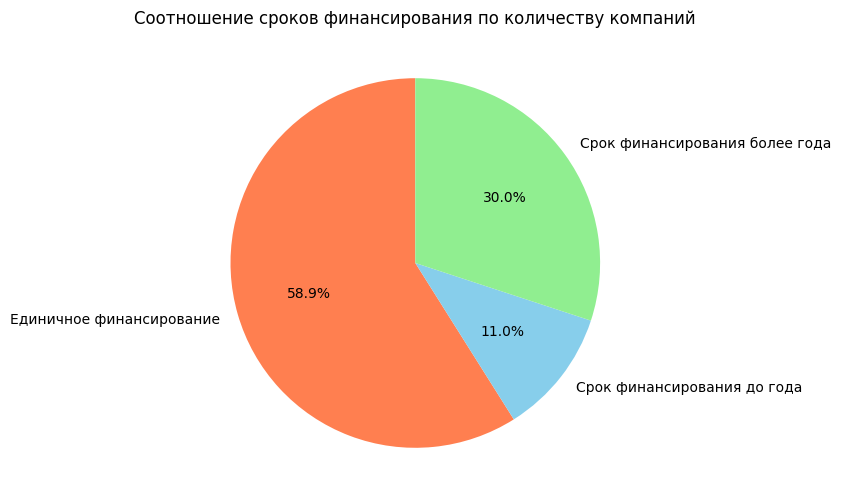

In [26]:
# Посчитаем количество компаний по группам:
companies_by_group = cb_investments['funding_group'].value_counts()

# Пропишем последовательность нашим группам и определим цвета:
categories = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года']
custom_colors = ['coral', 'skyblue', 'lightgreen']

# Выстроим наши группы в прописанном выше порядке:
companies_by_group = companies_by_group.reindex(categories)

# Построим круговую диаграмму по количеству компаний:
companies_by_group.plot(kind = 'pie',
                        ylabel = '',
                        autopct = '%1.1f%%',
                        startangle = 90,
                        colors = custom_colors,
                        labels = categories,
                        title = 'Соотношение сроков финансирования по количеству компаний',
                        figsize = (6, 6))

plt.show()

Теперь давайте построим круговую диаграмму, которая покажет, какую долю от общего объёма привлечённых средств получила каждая группа:

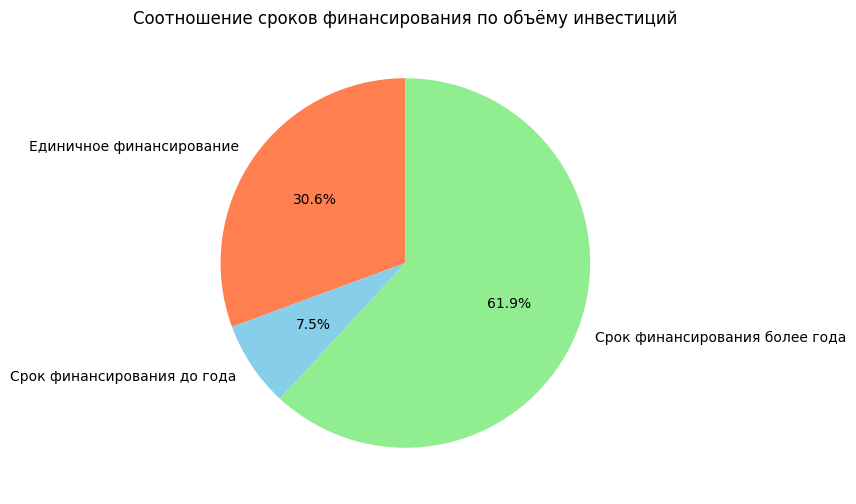

In [27]:
# Посчитаем сумму инвестиций для каждой группы:
investment_by_group = cb_investments.groupby('funding_group')['funding_total_usd'].sum()

# Выстроим наши группы в определенном порядке:
investment_by_group = investment_by_group.reindex(categories)

# Построим круговую диаграмму по объему инвестиций:
investment_by_group.plot(kind = 'pie',
                         ylabel = '',
                         autopct = '%1.1f%%',
                         startangle = 90,
                         colors = custom_colors,
                         labels = categories,
                         title = 'Соотношение сроков финансирования по объёму инвестиций',
                         figsize = (6, 6))

# Выведем наш график:
plt.show()

**Итог:** Мы наблюдаем, что большинство компаний (58,9% от общего числа компаний) получают единичное финансирование. Вероятно, такие компании быстро закрываются либо не продолжают развиваться. Долгоживущих компаний также немало - 30,1%. Меньше всего компаний в группе со сроком финансирования до года - 11%.

Также наблюдаем, что больше всего инвестиций (61,9%) приходится на компании, где срок финансирования больше года, что логично, ведь это чаще всего серьезные проекты, которые внушают доверие. На единичное финансирование приходится 30,6% инвестиций. Меньше всего инвестиций (7,5%) приходится на группу со сроком финансирования до года.

Резюмируем:
1. Большинство стартапов получают деньги один раз;
2. Почти все инвестиции забирают "долгожители";
3. Стартапы, у которых срок финансирования меньше года, проигрывают и по количеству, и по объему инвестиций.

[Вернуться к содержанию](#Содержание)

<a id="Выделение-средних-и-нишевых-сегментов-рынка"></a>
### 2.2. Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Давайте рассчитаем, как часто в датасете встречается каждый из сегментов:
1. Сегменты, к которым относится более 120 компаний, отнесем к массовым;
2. Сегменты, в которые входит от 35 до 120 включительно, - к средним;
3. Сегменты до 35 компаний - к нишевым.

Также рассчитаем, сколько сегментов попадает в каждую из категорий:

In [28]:
# Отфильтруем датафрейм, убрав нашу заглушку "не указано" из столбца market:
clean_market = cb_investments[cb_investments['market'] != 'не указано']

# Посчитаем количество компаний по сегментам:
market_counts_clean = clean_market['market'].value_counts()

# Создадим функцию для деления на категории:
def categorize_market_size(count):
    if count > 120:
        return 'Массовые'
    elif 35 <= count <= 120:
        return 'Средние'
    else:
        return 'Нишевые'

# Применим функцию:   
market_categories_clean = market_counts_clean.apply(categorize_market_size)

# Выведем результат:
print('Распределение количества сегментов по категориям:')
print(market_categories_clean.value_counts())

Распределение количества сегментов по категориям:
count
Нишевые     289
Средние      57
Массовые     48
Name: count, dtype: int64


В категорию нишевых попало 289 сегментов, средних - 57 сегмент, а массовых - 48 (наша заглушка "не указано" была бы здесь 49 сегментом).

Теперь давайте построим график распределения количества компаний в сегментах:

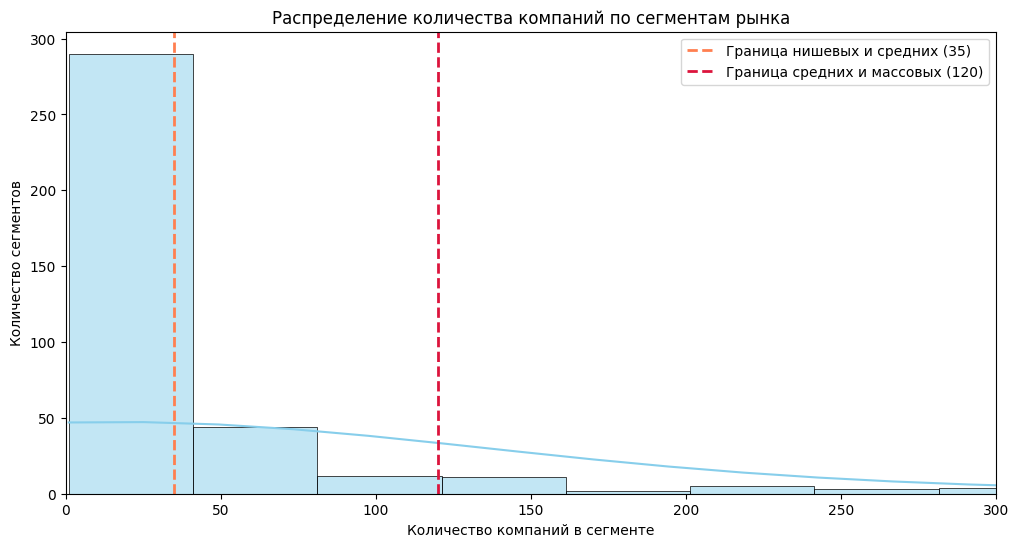

In [29]:
plt.figure(figsize = (12, 6))

# Построим гистограмму:
sns.histplot(market_counts_clean,
             bins = 120,
             kde = True,
             color = 'skyblue')

# Добавим границы наших категорий:
plt.axvline(x = 35,
            color = 'coral',
            linestyle = '--',
            linewidth = 2,
            label = 'Граница нишевых и средних (35)')

plt.axvline(x = 120,
            color = 'crimson',
            linestyle = '--',
            linewidth = 2,
            label = 'Граница средних и массовых (120)')

# Добавим оформление графика:
plt.title('Распределение количества компаний по сегментам рынка')
plt.xlabel('Количество компаний в сегменте')
plt.ylabel('Количество сегментов')
plt.legend()

# Ограничим по оси Х, чтобы улучшить визуальное восприятие:
plt.xlim(0, 300)

# Выведем наш график:
plt.show()

Согласно графику мы видим, что на рынке большое количество мелких ниш, т.е. очень узкоспециализированных направлений (более 275), в которых запускаются до 35 стартапов в каждом.

Также наблюдаем, что количество массовых направлений не такое большое (что логично), однако туда идет большинство компаний. Они формируют длинный и плоский хвост, который уходит далеко вправо за отметку 300.

Давайте посчитаем количество компаний по нашим категориям:

In [30]:
# Сгруппируем по категориям и посчитаем количество компаний в них:
companies_by_category = market_counts_clean.groupby(market_categories_clean).sum()

# Выведем результат:
print('Распределение количества компаний по категориям сегментов:')
print(companies_by_category.sort_values(ascending = False))

Распределение количества компаний по категориям сегментов:
count
Массовые    33733
Средние      3841
Нишевые       830
Name: count, dtype: int64


"Массовость" массовой категории подтверждается.

Анализировать сотни мелких ниш по отдельности нет смысла, поэтому давайте оптимизируем наши данные: оставим в столбце `market` только массовые сегменты, а для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних:

In [31]:
# Определим индексы серий с названиями сегментов:
mid_segments = market_counts_clean[(market_counts_clean >= 35) & (market_counts_clean <= 120)].index
niche_segments = market_counts_clean[market_counts_clean < 35].index

# Поставим наши заглушки:
cb_investments.loc[cb_investments['market'].isin(mid_segments), 'market'] = 'mid'
cb_investments.loc[cb_investments['market'].isin(niche_segments), 'market'] = 'niche'

Проверим, что у нас получилось:

In [32]:
# Выведем уникальные значения:
cb_investments['market'].unique()

array(['Education', 'не указано', 'mid', 'Social Media',
       'Hardware + Software', 'Biotechnology', 'Hospitality',
       'Enterprise Software', 'Manufacturing', 'Finance', 'Design',
       'niche', 'Nonprofits', 'Software', 'Curated Web', 'Health Care',
       'Health and Wellness', 'Clean Technology', 'Web Hosting',
       'E-Commerce', 'Automotive', 'Medical', 'Fashion', 'Security',
       'Networking', 'Analytics', 'Semiconductors', 'Public Relations',
       'Travel', 'Consulting', 'Real Estate', 'Technology', 'Music',
       'Advertising', 'Games', 'Mobile', 'Internet', 'Sports',
       'Photography', 'News', 'Search', 'Messaging', 'Video',
       'Marketplaces', 'Entertainment', 'SaaS', 'Cloud Computing',
       'Big Data', 'Apps', 'Social Network Media', 'Startups'],
      dtype=object)

Видим, что сохранились наши массовые сегменты, все нишевые и средние объединились в `niche` и `mid` соответственно. Также присутствует наша заглушка `'не указано'`.

**Итог:** Мы категорировали данные по "популярности" сегментов среди компаний, представленных в датасете, разделив сами сегменты на массовые (сегменты, к которым относится более 120 компаний), средние (сегменты с 35-120 компаниями) и нишевые (до 35 компаний в сегменте). Так мы получили, что к массовым относится 48 сегментов, к средним - 57, а к нишевым - 289. Мы установили, что на рынке большое количество мелких ниш, т.е. очень узкоспециализированных направлений, в которых запускаются до 35 стартапов в каждом. Также было установлено, что количество массовых направлений не такое большое, однако туда идет большинство компаний.

Анализировать сотни мелких ниш по отдельности нет смысла, поэтому было принято решение оставить в столбце `market` только массовые сегменты, а для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних.

[Вернуться к содержанию](#Содержание)

<a id="Результат-инжиниринга-признаков"></a>
### 2.3. Результат инжиниринга признаков

#### Группы по срокам финансирования

Мы разделили наши компании на три группы по срокам финансирования и получили следующее:

Большинство компаний (58,9% от общего числа компаний) получают единичное финансирование. Вероятно, такие компании быстро закрываются либо не продолжают развиваться. Долгоживущих компаний также немало - 30,1%. Меньше всего компаний в группе со сроком финансирования до года - 11%.

Также установили, что больше всего инвестиций (61,9%) приходится на компании, где срок финансирования больше года, что логично, ведь это чаще всего серьезные проекты, которые внушают доверие. На единичное финансирование приходится 30,6% инвестиций. Меньше всего инвестиций (7,5%) приходится на группу со сроком финансирования до года.

#### Выделение средних и нишевых сегментов рынка

Мы разделили сегменты, в которых работают компании, по принципу массовости использования и получили следующие результаты:
1. Массовых сегментов (сегменты, в которых работает больше 120 компаний) - 48;
2. Средних (сегменты, в которых работает от 35 до 120 компаний включительно) - 57;
3. Нишевых (сегменты, в которых работает до 35 компаний) - 298.

Это указывает на большое количество мелких ниш на рынке, т.е. очень узкоспециализированных направлений, в которых запускаются до 35 стартапов в каждом. Также было установлено, что количество массовых направлений не такое большое, однако туда идет большинство компаний.

Было принято решение оставить в столбце `market` только массовые сегменты, а для остальных сегментов заменим значения на заглушки — `niche` для нишевых и `mid` для средних, ведь в рамках нашего исследования анализировать сотни мелких ниш по отдельности нет смысла.

[Вернуться к содержанию](#Содержание)

<a id="Работа-с-выбросами-и-анализ"></a>
## 3. Работа с выбросами и анализ

<a id="Анализируем-и-помечаем-выбросы-в-каждом-из-сегментов"></a>
### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Давайте по нашему столбцу `funding_total_usd` построим график размаха и оценим, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся:

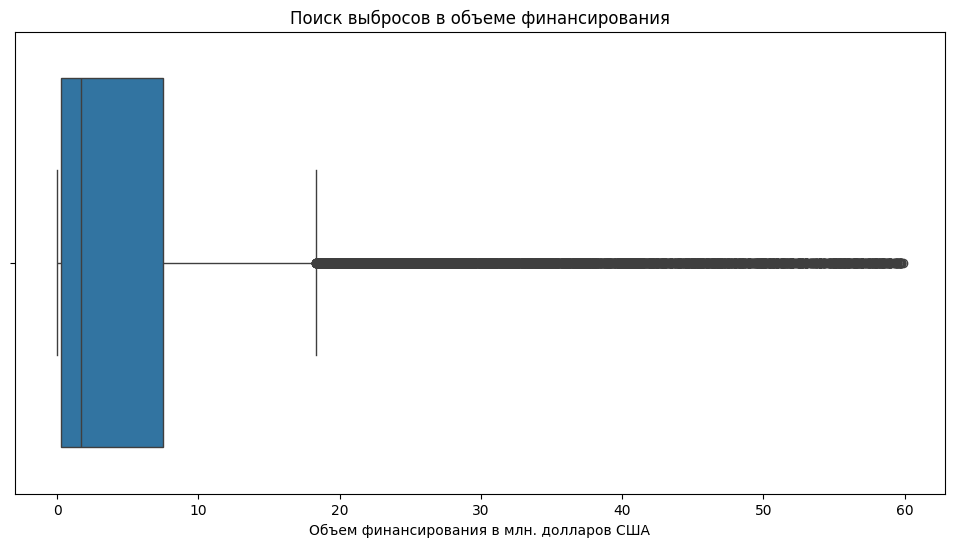

In [33]:
plt.figure(figsize = (12, 6))

# Установим лимит по 95-му процентилю, чтобы исключить аномально высокие значения финансирования (и улучшить визульное восприятие):
max_limit = cb_investments['funding_total_usd'].quantile(0.95)
filtered_funding_total_usd = cb_investments[cb_investments['funding_total_usd'] < max_limit].copy()

# Переведем суммы финансирования в миллионы для улучшения визуального восприятия графика:
filtered_funding_total_usd['funding_total_mil_usd'] = filtered_funding_total_usd['funding_total_usd'] / 1000000

# Построим ящики с усами:
sns.boxplot(data = filtered_funding_total_usd, x = 'funding_total_mil_usd')

# Оформим график:
plt.title('Поиск выбросов в объеме финансирования')
plt.xlabel('Объем финансирования в млн. долларов США')

# Выведем наш график:
plt.show()

На основе нашего графика мы можем сделать вывод, что типичный размер общего финансирования для одной компании лежит в диапазоне от 0 до примерно 18 миллионов долларов, так как на этой отметке заканчивается правый "ус" нашей диаграммы размаха. Также видим, что в основном инвестиции сосредоточены в диапазоне примерно от 0,5 до 7 миллионов долларов с медианным значением около 2 миллионов долларов. Все суммы, которые превышают границу в 18 миллионов долларов, формируют на графике линию из плотно размещенных точек. Мы их будем считать выбивающимися (аномальными) для рассматриваемого периода. Эти точки представляют собой исключительные и слишком крупные для данного рынка инвестиции.

Давайте определим компании с аномальным объёмом общего финансирования. Будем использовать метод IQR отдельно по каждому сегменту и на основании этого создадим столбец `is_anomaly` с бинарными признаком аномальности. Далее определим сегменты рынка с наибольшей долей компаний с аномальным финансированием и выведем топ-10 таких сегментов:

In [34]:
# Посчитаем квартили и границу аномальных значений:
q1 = cb_investments.groupby('market')['funding_total_usd'].quantile(0.25)
q3 = cb_investments.groupby('market')['funding_total_usd'].quantile(0.75)
upper_bound = q3 + 1.5 * (q3 - q1)

# Выше мы получили серию, поэтому сделаем из неё датафрейм:
bounds_df = upper_bound.to_frame(name = 'upper_bound').reset_index()

# Объединим с исходным датафреймом:
cb_investments = cb_investments.merge(bounds_df, on = 'market', how = 'left')

# Создадим столбец с бинарным признаком аномальности:
cb_investments['is_anomaly'] = (cb_investments['funding_total_usd'] > cb_investments['upper_bound'])


# Сгруппируем данные по сегментам и посчитаем долю компаний с аномальным финансированием:
market_anomaly = cb_investments.groupby('market')['is_anomaly'].mean().reset_index()
market_anomaly['is_anomaly'] = (market_anomaly['is_anomaly'] * 100).round(2)

# Сформируем топ-10 сегментов: 
top_anomaly_markets = market_anomaly.sort_values(by = 'is_anomaly', ascending = False).set_index('market').head(10)

# Выведем результат:
print('Топ-10 сегментов рынка с наибольшей долей аномального финансирования')
top_anomaly_markets

Топ-10 сегментов рынка с наибольшей долей аномального финансирования


,is_anomaly
market,
Real Estate,17.20
Entertainment,16.67
Consulting,16.62
Search,16.49
Cloud Computing,16.45
Photography,16.18
SaaS,16.18
Technology,15.97
Video,15.96


**Итог:** Мы установили, что типичный размер финансирования для одной компании находится в диапазоне от 0 до 18 миллионов долларов. Основные инвестиции сосредоточены в границах от 0,5 до 7 миллионов долларов с медианой около 2 миллионов долларов. Все суммы свыше 18 миллионов долларов формируют линию из точек-аномалий. Мы приняли их как аномальные для рассматриваемого периода с помощью метода IQR, создав столбец с бинарным признаком `is_anomaly`.

Также мы рассчитали долю аномального финансирования по сегментам и составили топ-10 сегментов, где аномально высокие инвестиции встречаются чаще всего. Чаще всего выбивающее финансирование имеют `Real Estate` (17,2%), `Entertainment` (16,67%) и `Consulting` (16,62%). Далее распредлены сегменты в топе так: `Search` (16,49%), `Cloud Computing` (16,45%), `Photography` (16,18%), `SaaS` (16,18%), `Technology` (15,97%), `Video` (15,96%). Также в топ вошел нишевый сегмент - 15,9% компаний имеют аномальное финансирование.

[Вернуться к содержанию](#Содержание)

<a id="Определяем-границы-рассматриваемого-периода"></a>
### 3.2. Определяем границы рассматриваемого периода, отбрасываем аномалии

Давайте проверим по датасету, можно ли считать, что нам предоставили полные данные за 2014 год. Построим график распределения инвестиционных данных по месяцам за 2014 год:

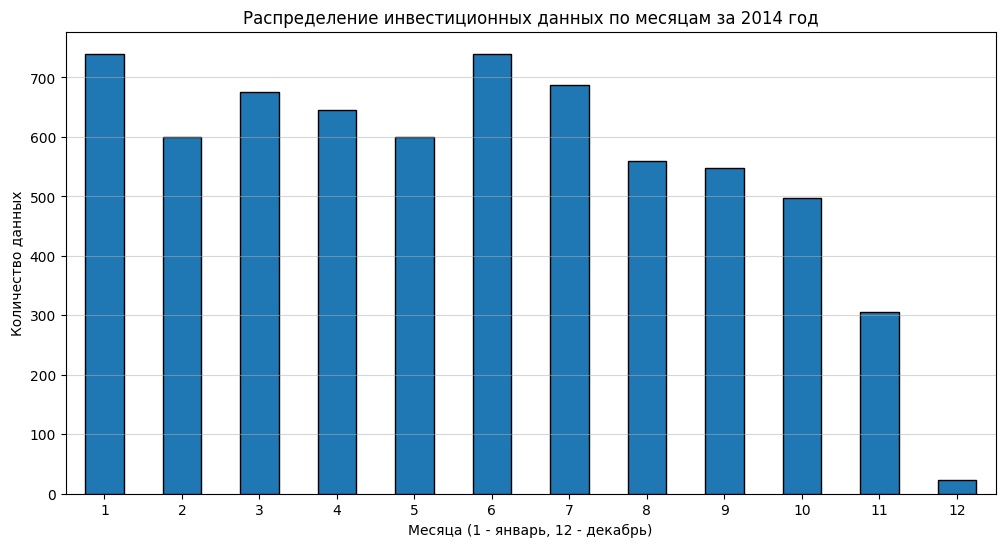

In [35]:
# Выделим год и месяц:
cb_investments['funding_year'] = cb_investments['mid_funding_at'].dt.year
cb_investments['funding_month'] = cb_investments['mid_funding_at'].dt.month

# Отфильтруем данные за 2014 год и сделаем распределение по месяцам:
data_2014 = cb_investments[cb_investments['funding_year'] == 2014]
data_2014_months = data_2014['funding_month'].value_counts().sort_index()

# Построим столбчатую диаграмму на основе наших данных:
data_2014_months_bar = data_2014_months.plot.bar(title = 'Распределение инвестиционных данных по месяцам за 2014 год',
                                                 xlabel = 'Месяца (1 - январь, 12 - декабрь)',
                                                 ylabel = 'Количество данных',
                                                 edgecolor = 'black',
                                                 figsize = (12, 6),
                                                 rot = 0)

# Сделаем полупрозрачную сетку по оси Y:
plt.grid(axis = 'y', alpha = 0.5)

# Выведем наш график:
plt.show()

Данные за 2014 год нельзя считать полными. Мы наблюдаем, что в конце года количество данных становится сильно меньше. Скорее всего при выгрузке в ноябре-декабре данные оборвались. Также наблюдаем, что больше всего инвестиций было в январе и июне.

Теперь давайте исключим из датасета компании, которые мы ранее посчитали получившими аномальное финансирование. Будем опираться на наш столбец с бинарными признаком аномальности `is_anomaly`. Затем на основе столбцов `funding_year` (который мы создали выше) и `funding_rounds` оставим в датасете данные только об определённых компаниях, которые получали финансирование в годы, когда было зафиксировано 50 или более раундов финансирования. Приступим:

In [36]:
# Отфильтруем и оставим только компании с типичным финансированием:
cb_filtered = cb_investments[cb_investments['is_anomaly'] == 0]

# Сгруппируем по годам и посчитаем количество раундов для каждого:
rounds_year = cb_filtered.groupby('funding_year')['funding_rounds'].sum()

# Оставим только те года, где 50 и больше раундов финансирования:
rounds_50_years = rounds_year[rounds_year >= 50]

# Выведем отобранные годы и их количество раундов:
print('Годы, где зафиксировано 50 и больше раундов финансирования')
print(rounds_50_years.sort_values(ascending = False))

# Оставим те компании, которые получили финансирование в отобранные выше годы:
cb_rounds_50 = cb_filtered[cb_filtered['funding_year'].isin(rounds_50_years.index)].copy()

# Проверим, как изменился наш датасет:
print(f'\nВ датасете осталось {len(cb_rounds_50)} строк из {len(cb_investments)}')

Годы, где зафиксировано 50 и больше раундов финансирования
funding_year
2013    12880.0
2012     9707.0
2011     7578.0
2014     7124.0
2010     6136.0
2009     4617.0
2008     3663.0
2007     2842.0
2006     1849.0
2005      948.0
2004      181.0
2003      125.0
2000      113.0
2002       98.0
2001       66.0
Name: funding_rounds, dtype: float64

В датасете осталось 35589 строк из 40907


Готово.

**Итог:** В рамках этого пункта мы проверили полноту данных за 2014 год и установили, что данные неполные, так как данных за ноябрь и декабрь сильно меньше, чем в остальные месяца. Скорее всего при выгрузке в ноябре-декабре данные оборвались. Также мы отметили, что больше всего инвестиций было в январе и июне.

Затем мы исключили из датасета компании, которые имели аномальное финансирование, которое отражено было в нашем столбце `is_anomaly`. Также мы оставили в датасете только те годы, когда в год было 50 и более раундов финансирования и получили отфильтрованный датасет `cb_rounds_50` (с 2000 по 2014 годы), который содержит 35588 строк (до фильтрации было 40907).

[Вернуться к содержанию](#Содержание)

<a id="Анализ-типов-финансирования-по-объёму-и-популярности"></a>
### 3.3. Анализ типов финансирования по объёму и популярности

Давайте узнаем, какие типы финансирования в сумме привлекли больше всего денег. Для этого построим график, который нам это покажет:

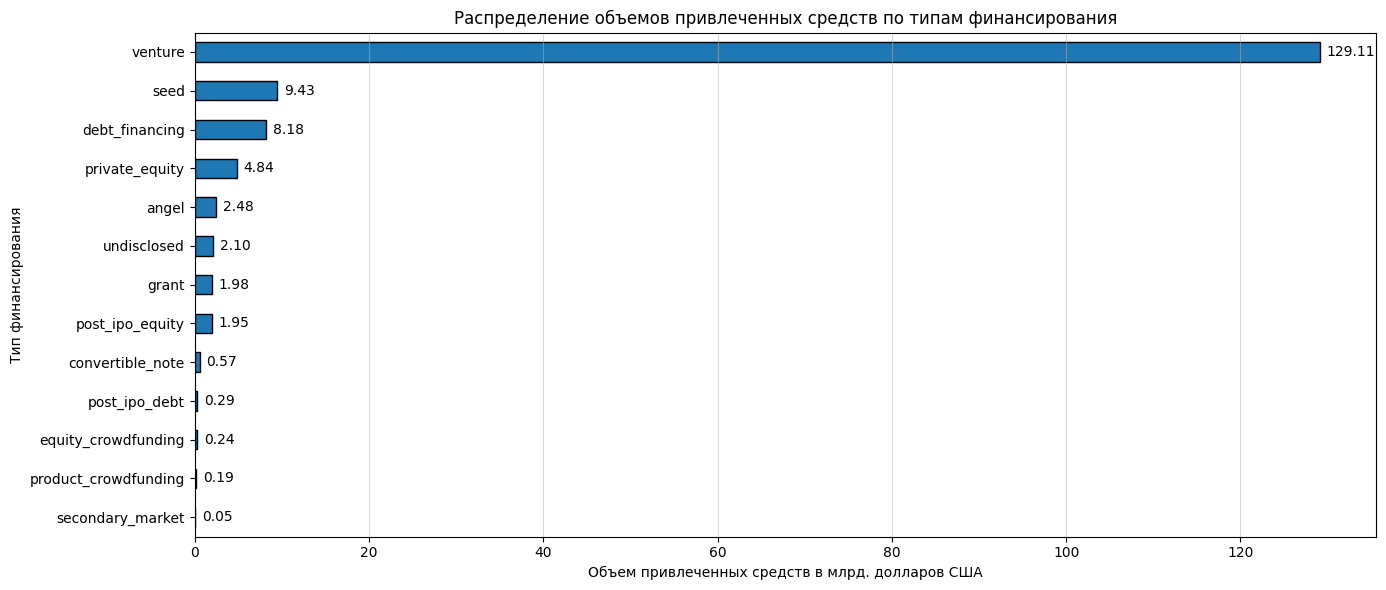

In [37]:
# Создадим список с типами финансирования:
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                 'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                 'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

# Посчитаем сумму для каждого типа финансирования в миллиардах долларов:
funding_sum = (cb_rounds_50[funding_types] / 1000000000).sum().sort_values(ascending = True)


# Построим линейчатую диаграмму на основе наших данных:
funding_sum_barh = funding_sum.plot.barh(title = 'Распределение объемов привлеченных средств по типам финансирования',
                                         xlabel = 'Объем привлеченных средств в млрд. долларов США',
                                         ylabel = 'Тип финансирования',
                                         edgecolor = 'black',
                                         figsize = (14, 6))

# Создадим функцию, которая будем в дальнейшем использовать для формирования подписей:
def add_bar_labels(ax, is_horizontal=True):
    """
    Функция добавляет подписи значений ко всем столбцам графика.
    
    Параметры:
    ax: Объект, на котором построен график.
    is_horizontal (bool): True для горизонтальных столбцов (barh), 
                          False для вертикальных (bar).
    """
    for container in ax.containers:
        for bar in container:
            if is_horizontal:
                value = bar.get_width()
                xy = (value, bar.get_y() + bar.get_height() / 2)
                xytext = (5, 0)
                ha, va = 'left', 'center'
            else:
                value = bar.get_height()
                xy = (bar.get_x() + bar.get_width() / 2, value)
                xytext = (0, 5)
                ha, va = 'center', 'bottom'
                
            # Если число целое (например, 15.0), убираем точку и выводим как 15:
            if value % 1 == 0:
                label = f'{int(value)}'
            # Если число дробное (например, 15.345), округляем ровно до 2 знаков: 15.35:
            else:
                label = f'{value:.2f}'
                
            ax.annotate(label,
                        xy = xy,
                        xytext = xytext,
                        textcoords = 'offset points',
                        ha = ha, va = va)

# Подпишем значения рядом с нашими столбцами, используя функцию:
add_bar_labels(funding_sum_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis = 'x', alpha = 0.5)

# Выведем наш график:
plt.tight_layout()
plt.show()

На основе полученных данных, мы можем сделать вывод, что больше всего средств было привлечено в рамках венчурных инвестиций (`venture`) - 129,09 миллиардов долларов США, инвестиций на посевной стадии (`seed`) - 9,43 миллиардов и долгового финансирования (`debt_financing`) - 8,18 миллиардов.

Далее идут прямые частные вложения (`private_equity`) - 4,84 миллиарда долларов США, инвестиции от бизнес-ангелов (`angel`) - 2,48 миллиарда, а также финансирование нераскрытого типа (`undisclosed`) - 2,10 миллиарда, за ними следуют полученные гранты (`grant`) - 1,98 миллиарда и финансирование после IPO (`post_ipo_equity`) - 1,95 миллиарда. Наименьшие объемы средств были привлечены через конвертируемые займы (`convertible_note`) - 0,57 миллиарда долларов США, долговое финансирование после IPO (`post_ipo_debt`) - 0,29 миллиарда, долевой краудфандинг (`equity_crowdfunding`) - 0,24 миллиарда, продуктовый краудфандинг (`product_crowdfunding`) - 0,19 миллиарда и, наконец, сделки на вторичном рынке (`secondary_market`) - всего 0,05 миллиарда долларов США.

Теперь давайте узнаем, какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз. Для этого построим график, который покажет популярность разных типов финансирования:

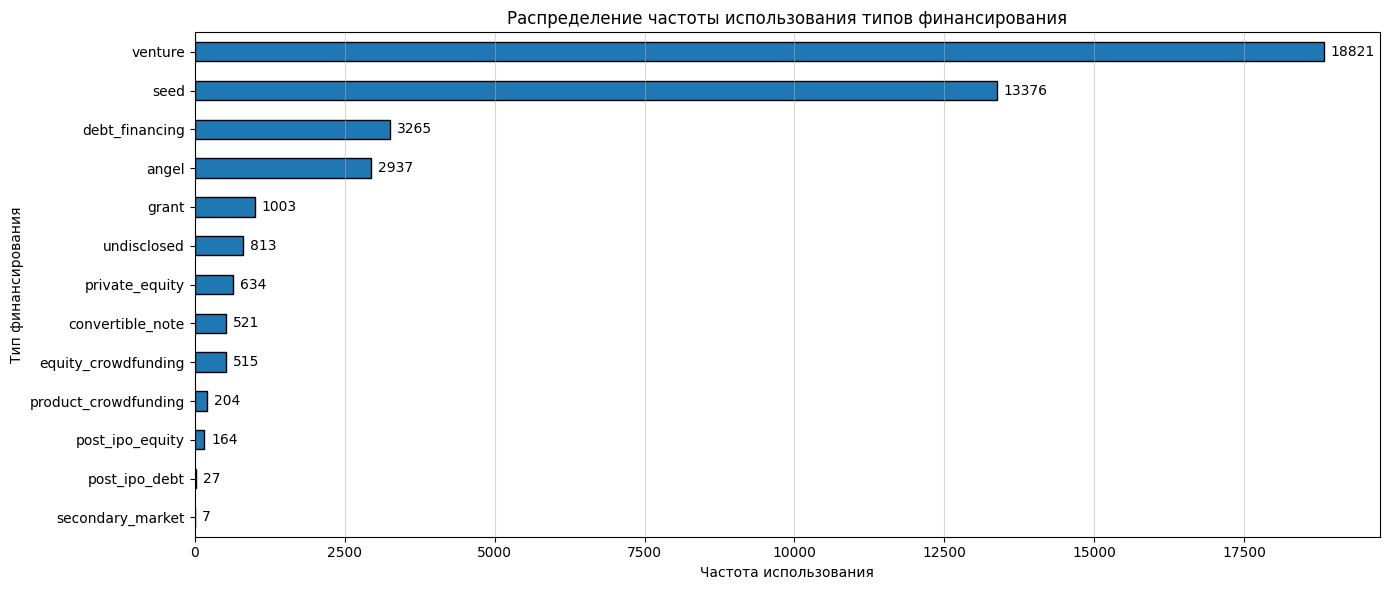

In [38]:
# Посчитаем сколько раз использовался каждый тип финансирования (значит, что что-то инвестировали):
funding_popularity = (cb_rounds_50[funding_types] > 0).sum().sort_values(ascending=True)

# Построим линейчатую диаграмму на основе наших данных:
funding_popularity_barh = funding_popularity.plot.barh(title = 'Распределение частоты использования типов финансирования',
                                                       xlabel = 'Частота использования',
                                                       ylabel = 'Тип финансирования',
                                                       edgecolor = 'black',
                                                       figsize = (14, 6))

# Подпишем значения рядом с нашими столбцами:
add_bar_labels(funding_popularity_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis = 'x', alpha = 0.5)

# Выведем наш график:
plt.tight_layout()
plt.show()

Можем сделать вывод, что чаще всего компании привлекали средства в рамках венчурных инвестиций (`venture`) - этот тип финансирования использовался 18820 раз. На втором месте по популярности находятся инвестиции на посевной стадии (`seed`), которые встречаются в датасете 13375 раз.

За ними следуют долговое финансирование (`debt_financing`) - 3265 раз, и инвестиции от бизнес-ангелов (`angel`) — 2937 раз, полученные гранты (`grant`) — 1003 раза, финансирование нераскрытого типа (`undisclosed`) — 813 раз, прямые частные вложения (`private_equity`) — 634 раза, конвертируемые займы (`convertible_note`) — 521 раз, долевой краудфандинг (`equity_crowdfunding`) — 515 раз, продуктовый краудфандинг (`product_crowdfunding`) — 204 раза и финансирование после IPO (`post_ipo_equity`) — 164 раза. Реже всего компании привлекали средства в рамках долгового финансирования после IPO (`post_ipo_debt`) и сделок на вторичном рынке (`secondary_market`) — они использовались всего 27 и 7 раз соответственно.

Сопоставим графики и разделим типы финансирования на следующие категории:
- Часто используется + Много денег: Венчурные инвестиции (`venture`) доминируют на рынке, занимают первое место как по количеству упоминаний (18820), так и по сумме привлечённых средств (129,09 миллиардов долларов США);
- Часто используется + Мало денег: Инвестиции на посевной стадии (`seed`), долговое финансирование (`debt_financing`) и инвестиции от бизнес-ангелов (`angel`) используются очень часто (13375, 3265 и 2938 раз соответственно), но характеризуются небольшими средними чеками, поэтому объемы привлеченных средств в рамках их не такие большие (9,43 миллиардов, 8,18 миллиардов и 2,48 миллиарда соответственно);
- Редко используются + Много денег: Прямые частные вложения (`private_equity`) и финансирование после IPO (`post_ipo_equity`) используются компаниями редко (634 и 164 раз соответственно), однако каждая отдельная сделка приносит огромные суммы (4,84 миллиарда и 1,95 миллиарда);
- Мало сделок + Мало денег: конвертируемые займы (`convertible_note`), долевой краудфандинг (`equity_crowdfunding`), продуктовый краудфандинг (`product_crowdfunding`), долговое IPO (`post_ipo_debt`) и вторичный рынок (`secondary_market`) являются редкими способами привлечения средств (521, 515, 204, 27 и 7 упоминаний соответственно) с минимальным объемом (0,57 миллиарда долларов, 0,24 миллиарда, 0,19 миллиарда, 0,29 миллиарда и 0,05 миллиарда долларов США соотвественно).

Давайте узнаем суммарные объёмы возвратов от разных типов финансирования за весь период. Для этого построим график на основе дополнительного датасета `cb_returns`:

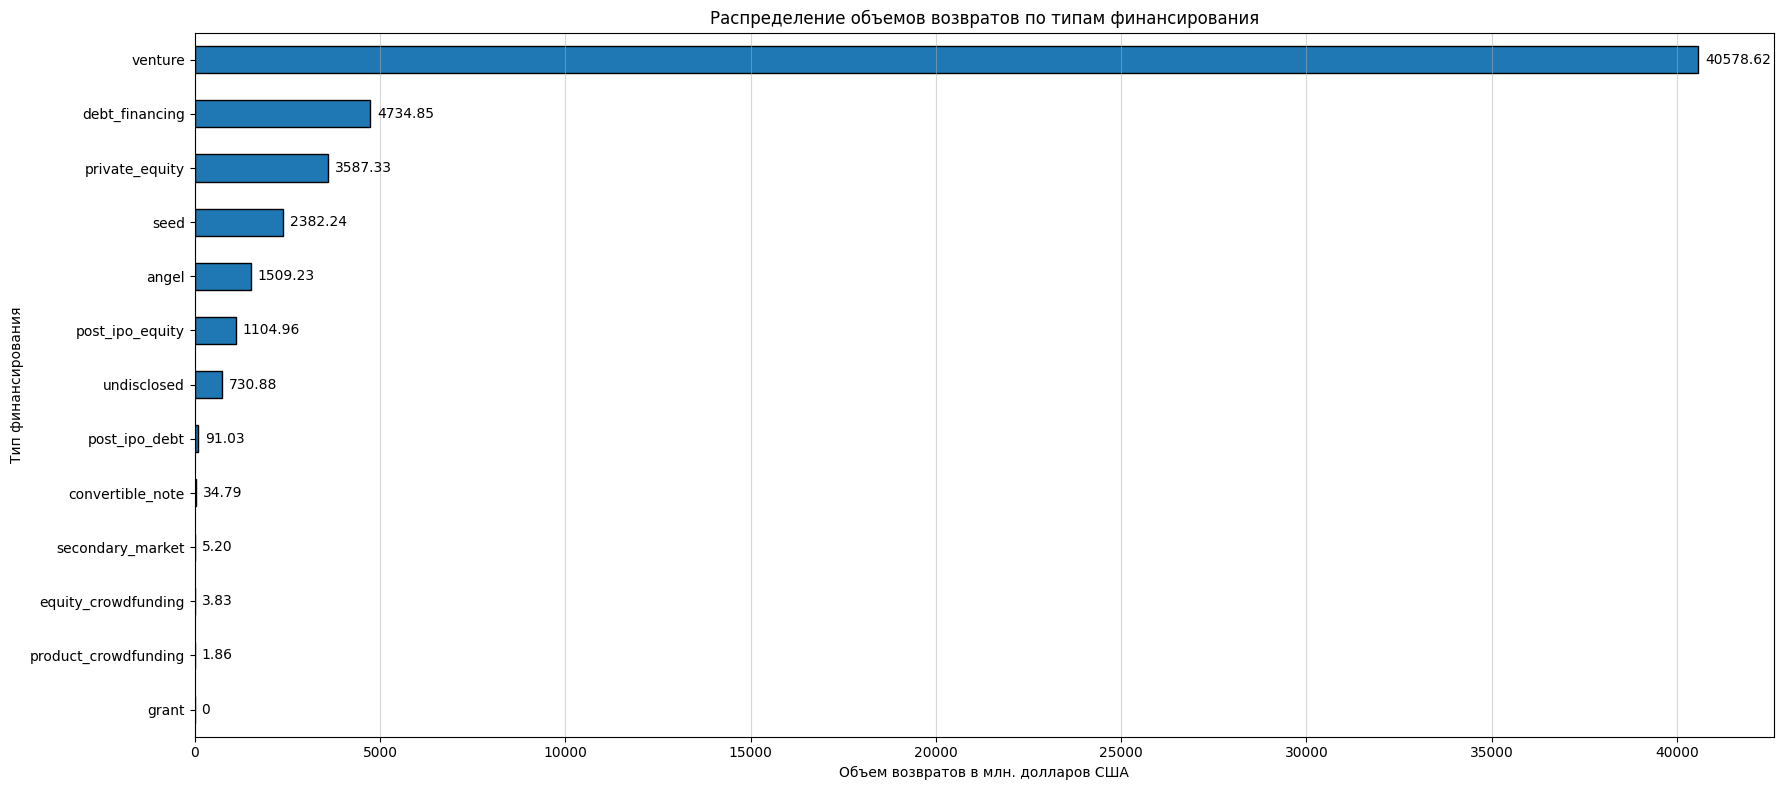

In [39]:
# Посчитаем сумму возврата для каждого типа финансирования в миллионах долларов:
return_funding_sum = cb_returns[funding_types].sum().sort_values(ascending = True)

# Построим линейчатую диаграмму на основе наших данных:
return_funding_sum_barh = return_funding_sum.plot.barh(title = 'Распределение объемов возвратов по типам финансирования',
                                                       xlabel = 'Объем возвратов в млн. долларов США',
                                                       ylabel = 'Тип финансирования',
                                                       edgecolor = 'black',
                                                       figsize = (18, 8))

# Подпишем значения рядом с нашими столбцами, используя функцию:
add_bar_labels(return_funding_sum_barh, is_horizontal = True)

# Сделаем полупрозрачную сетку по оси X:
plt.grid(axis = 'x', alpha = 0.5)

# Выведем наш график:
plt.tight_layout()
plt.show()

Мы можем сделать вывод, что самыми окупаемыми являются венчурные инвестиции (`venture`) — они вернули 40,58 миллиардов долларов США, далее идут долговое финансирование (`debt_financing`) - 4,73 миллиарда, прямые частные вложения (`private_equity`) - 3,59 миллиарда.

Затем идут инвестиции на посевной стадии (`seed`) — 2,39 миллиарда долларов США возврата, вложения от бизнес-ангелов (`angel`) — 1,5 миллиарда, финансирование после IPO (`post_ipo_equity`) — 1,1 миллиарда, а также финансирование нераскрытого типа (`undisclosed`) — 730,88 миллионов.

Небольшой объем возврата у следующих типов финансирования: долговое финансирование после IPO (`post_ipo_debt`) — 91,03 миллионов, конвертируемые займы (`convertible_note`) — 34,79 миллиона и сделки на вторичном рынке (`secondary_market`) — 5,20 миллионов. Замыкают список долевой краудфандинг (`equity_crowdfunding`) - 3,83 миллиона, продуктовый краудфандинг (`product_crowdfunding`) - 1,86 миллион. Гранты (`grant`) ничего не вернули, так как они являются безвозмездным финансированием, т.е. не предполагают возврата средств инвесторам.

**Итог:** Если сопоставить популярность типов финансирования, объемы привлечённых средств и объемы их последующих возвратов, мы можем сделать вывод, что абсолютным фаворитом рынка по всем трем пунктам являются венчурные инвестиции (`venture`). Они чаще всего использовались компаниями (18820 раз) и привлекли больше всего денег (129,09 миллиардов долларов США), а также принесли самый большой объём возвратов  — 40,58 миллиардов.

По результам исследования можем выделить интересные пункты:
1. Часто используется + Привлекает мало денег: Инвестиции на посевной стадии (`seed`), долговое финансирование (`debt_financing`) и инвестиции от бизнес-ангелов (`angel`) используются очень часто (13375, 3265 и 2938 раз соответственно), но характеризуются небольшими средними чеками, поэтому объемы привлеченных средств в рамках их не такие большие (9,43 миллиардов, 8,18 миллиардов и 2,48 миллиарда соответственно);
2. Редко используются + Привлекает много денег: Прямые частные вложения (`private_equity`) и финансирование после IPO (`post_ipo_equity`) используются компаниями редко (634 и 164 раз соответственно), однако каждая отдельная сделка приносит огромные суммы (4,84 миллиарда и 1,95 миллиарда).

По возвратам на втором и на третьем месте распологаются долговое финансирование (`debt_financing`) - 4,73 миллиарда возврата и прямые частные вложения (`private_equity`) - 3,59 миллиарда возврата. Меньше всего по возвратам у долевого краудфандинга (`equity_crowdfunding`) - 3,83 миллиона, продуктового краудфандинга (`product_crowdfunding`) - 1,86 миллион. Гранты (`grant`) ничего не вернули, так как они являются безвозмездным финансированием, т.е. не предполагают возврата средств инвесторам.

[Вернуться к содержанию](#Содержание)

<a id="Результат-работы-с-выбросами-и-анализа"></a>
### 3.4. Результат работы с выбросами и анализа

#### Анализ выбросов в каждом из сегментов

Мы установили, что типичный размер финансирования для одной компании находится в диапазоне от 0 до 18 миллионов долларов США. Основные инвестиции сосредоточены в границах от 0,5 до 7 миллионов с медианой около 2 миллионов. Все суммы свыше 18 миллионов формируют линию из точек-аномалий. Мы приняли их как аномальные для рассматриваемого периода с помощью метода IQR, создав столбец с бинарным признаком `is_anomaly`.

Также мы рассчитали долю аномального финансирования по сегментам и составили топ-10 сегментов, где аномально высокие инвестиции встречаются чаще всего. Чаще всего выбивающее финансирование имеют `Real Estate` (17,2%), `Entertainment` (16,67%) и `Consulting` (16,62%). Далее распредлены сегменты в топе так: `Search` (16,49%), `Cloud Computing` (16,45%), `Photography` (16,18%), `SaaS` (16,18%), `Technology` (15,97%), `Video` (15,96%). Также в топ вошел нишевый сегмент - 15,9% компаний имеют аномальное финансирование.

#### Граница рассматриваемого периода, отброс аномалии

Мы установили, что данные за 2014 неполные, так как данных за ноябрь и декабрь сильно меньше, чем в остальные месяца. Возможно причиной этому мы посчитали, что при выгрузке в ноябре-декабре данные оборвались. Также мы отметили, что больше всего инвестиций было в январе и июне.

Из датасета нами были исключены компании, которые имели аномальное финансирование, которое отражено было в нашем столбце `is_anomaly`. Также мы оставили в датасете только те годы, когда в год было 50 и более раундов финансирования и получили отфильтрованный датасет `cb_rounds_50`, который содержит 35588 строк (до фильтрации было 40907).

#### Анализ типов финансирования по объёму и популярности

Мы установили, что абсолютным фаворитом рынка по объему привлеченных средств, по популярности и по возвратам являются венчурные инвестиции (`venture`). Они чаще всего использовались компаниями (18820 раз) и привлекли больше всего денег (129,09 миллиардов долларов США), а также принесли самый большой объём возвратов  — 40,58 миллиардов.

По результам исследования также выделили интересные пункты:
1. Часто используется + Привлекает мало денег: Инвестиции на посевной стадии (`seed`), долговое финансирование (`debt_financing`) и инвестиции от бизнес-ангелов (`angel`) используются очень часто (13375, 3265 и 2938 раз соответственно), но характеризуются небольшими средними чеками, поэтому объемы привлеченных средств в рамках их не такие большие (9,43 миллиардов, 8,18 миллиардов и 2,48 миллиарда соответственно);
2. Редко используется + Привлекает много денег: Прямые частные вложения (`private_equity`) и финансирование после IPO (`post_ipo_equity`) используются компаниями редко (634 и 164 раз соответственно), однако каждая отдельная сделка приносит огромные суммы (4,84 миллиарда и 1,95 миллиарда).

По возвратам на втором и на третьем месте распологаются долговое финансирование (`debt_financing`) - 4,73 миллиарда возврата и прямые частные вложения (`private_equity`) - 3,59 миллиарда возврата. Меньше всего по возвратам у долевого краудфандинга (`equity_crowdfunding`) - 3,83 миллиона, продуктового краудфандинга (`product_crowdfunding`) - 1,86 миллион. Гранты (`grant`) ничего не вернули, так как они являются безвозмездным финансированием, т.е. не предполагают возврата средств инвесторам.

[Вернуться к содержанию](#Содержание)

<a id="Анализ-динамики"></a>
## 4. Анализ динамики

<a id="Динамика-предоставления-финансирования-по-годам"></a>
### 4.1. Динамика предоставления финансирования по годам

Давайте изучим динамику предоставления финансирования по годам, но для начала посчитаем средний объём одного раунда финансирования для каждой компании. Сделаем это, опираясь на наши столбцы `funding_total_usd` и `funding_rounds`:

In [40]:
# Посчитаем средний объём одного раунда финансирования для каждой компании и сохраним его в отдельном столбце:
cb_rounds_50['avg_funding'] = cb_rounds_50['funding_total_usd'] / cb_rounds_50['funding_rounds']

Теперь приступим к анализу. Давайте построим график, который покажет динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования:

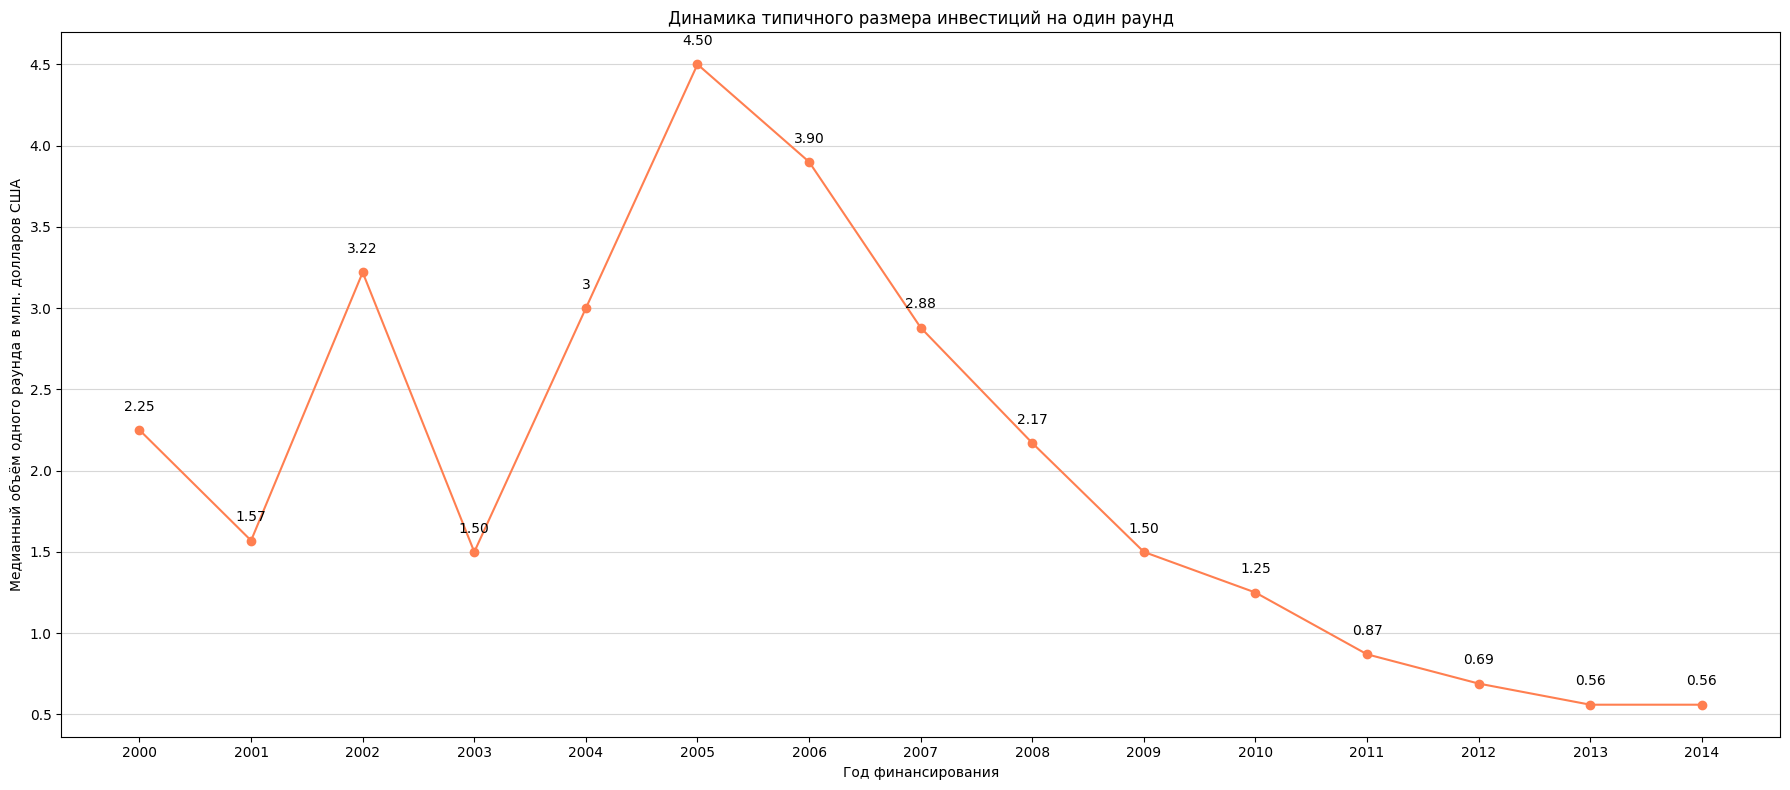

In [41]:
# Сгруппируем данные по годам и посчитаем медианное значение объёма одного раунда финансирования в миллионах долларов для каждого года:
avg_funding_per_year = (cb_rounds_50.groupby('funding_year')['avg_funding'].median() / 1000000).round(2)

# Построим линейный график на основе наших данных:
avg_funding_per_year_line = avg_funding_per_year.plot(kind= 'line',
                                                      title = 'Динамика типичного размера инвестиций на один раунд',
                                                      xlabel = 'Год финансирования',
                                                      ylabel = 'Медианный объём одного раунда в млн. долларов США',
                                                      color = 'coral',
                                                      marker = 'o',
                                                      figsize = (18, 8))

# Добавим подписи значений над каждой точкой графика:
def add_line_labels(series):
    """
    Параметры:
    series: Наша серия, на основе которой мы строили график.
    """
    for x, y in zip(series.index, series.values):
        # Если число целое (например, 15.0), убираем точку и выводим как 15:
        if y % 1 == 0:
            label = f'{int(y)}'
        # Если число дробное (например, 15.345), округляем ровно до 2 знаков: 15.35:
        else:
            label = f'{y:.2f}'
        
        plt.text(x = x, 
                 y = y + 0.1,
                 s = label,
                 ha = 'center',
                 va = 'bottom')

# Добавим подписи значений над каждой точкой, используя нашу функцию:
add_line_labels(avg_funding_per_year)

# Сделаем полупрозрачную сетку по оси Y:
plt.grid(axis = 'y', alpha = 0.5)

# Выведем наш график:
plt.xticks(avg_funding_per_year.index)
plt.tight_layout()
plt.show()

Видим, что в 2005 году типичный размер средств, собранных в рамках одного раунда, был максимальным и равнялся 4,5 миллиона долларов США, затем пошел на спад и в 2014 равнялся 0,56 миллиона.

Теперь давайте построим график, который отразит динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность):

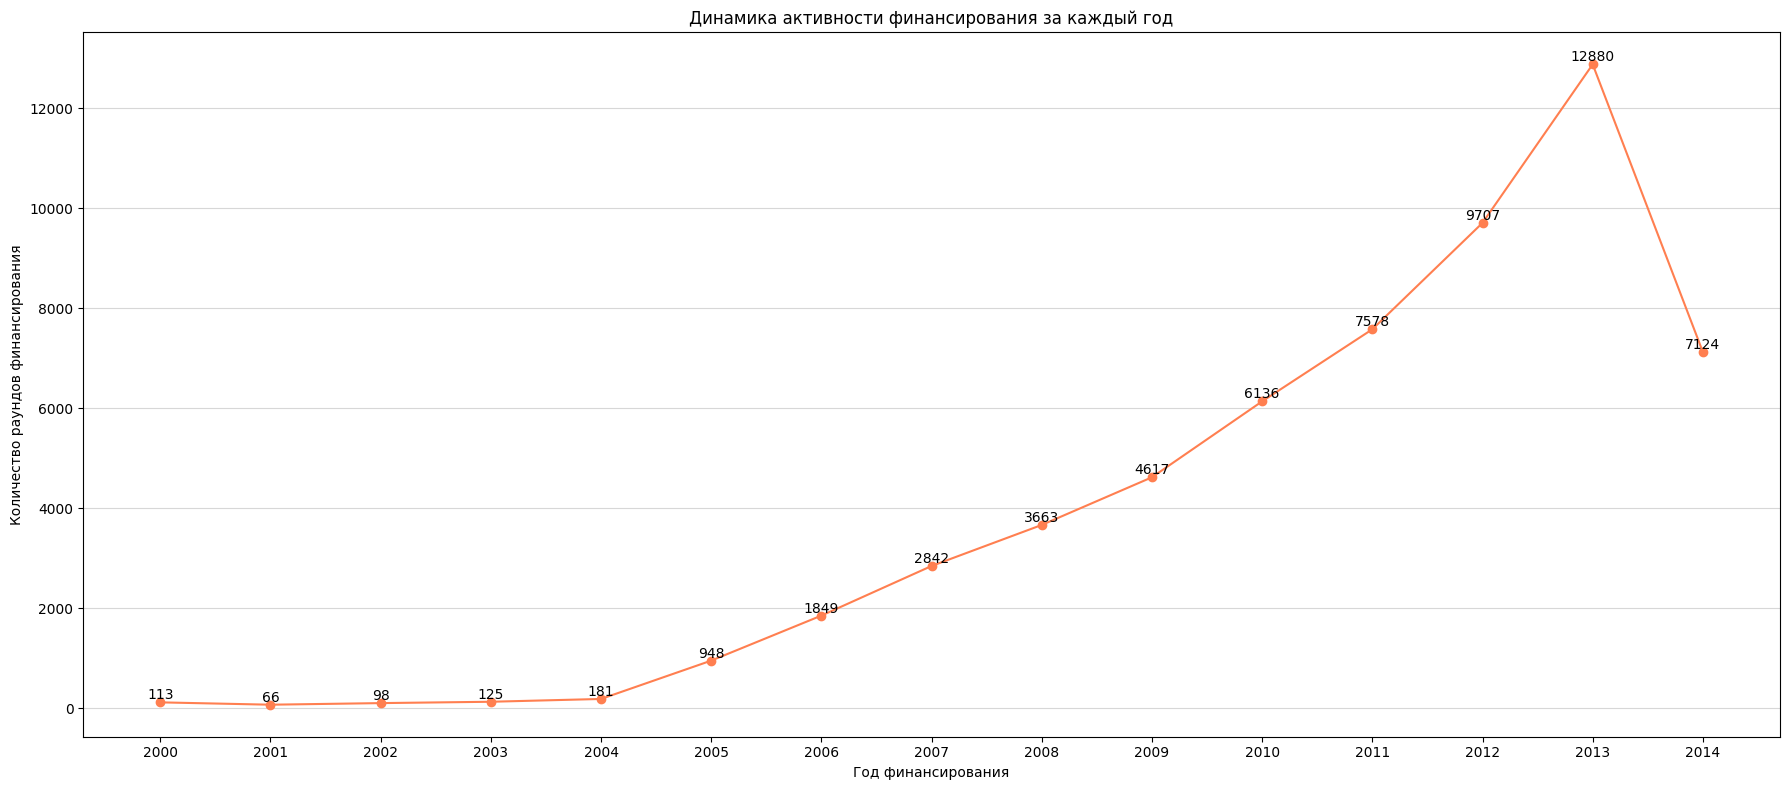

In [42]:
# Сгруппируем данные по годам и посчитаем количество раундов финансирования на каждый год:
rounds_count_per_year = cb_rounds_50.groupby('funding_year')['funding_rounds'].sum()

# Построим линейный график на основе наших данных:
rounds_count_per_year_line = rounds_count_per_year.plot(kind= 'line',
                                                        title = 'Динамика активности финансирования за каждый год',
                                                        xlabel = 'Год финансирования',
                                                        ylabel = 'Количество раундов финансирования',
                                                        color = 'coral',
                                                        marker = 'o',
                                                        figsize = (18, 8))

# Добавим подписи значений над каждой точкой:
add_line_labels(rounds_count_per_year)

# Сделаем полупрозрачную сетку по оси Y:
plt.grid(axis = 'y', alpha = 0.5)

# Выведем наш график:
plt.xticks(rounds_count_per_year.index)
plt.tight_layout()
plt.show()

Видим, что пик активности финансирования приходится на 2013 год.

По результатам исследования динамики предоставления финансирования по годам мы можем установить, что в 2014 году был минимальный средний объем одного раунда финансирования для каждой компании - 0,56 миллиона долларов США (ровно как и в 2013 году). Что касается количества раундов финансирования в 2014 году, оно равняется 7122. Для сравнения: в 2013 году был отмечен пик количества раундов - 12880, а до этого в 2012 году было 9707 раундов, в 2011 - 7578.

Выше мы установили, что данные за 2014 год неполные, поэтому этим можно объяснить "проседание" линии графика в 2014 году по активности финансирования.

**Итог:** В рамках этого пункта мы посчитали средний объем одного раунда финансирования для каждой компании и сохранили это значение в столбец `avg_funding`. Затем мы построили два графика и изучили динамику предоставления финансирования по годам. Нами было установлено:
1. Максимальный типичный размер средств, собранных в рамках одного раунда, был отмечен в 2005 году и равнялся 4,5 миллиона долларов США, затем пошел на спад;
2. В 2014 году был минимальный (для изучаемого периода) средний объем одного раунда финансирования для каждой компании - 0,56 миллиона долларов США (ровно как и в 2013 году). Что касается количества раундов финансирования в 2014 году, оно равняется 7122. Для сравнения: в 2013 году был отмечен пик количества раундов - 12880, а до этого в 2012 году было 9707 раундов, в 2011 - 7578. Такое "проседание" в 2014 году мы объясняем неполной данных за этот год.

[Вернуться к содержанию](#Содержание)

<a id="Динамика-размера-общего-финансирования-по-массовым-сегментам"></a>
### 4.2. Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Давайте составим сводную таблицу, в которой укажем суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберем из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013:

In [43]:
# Построим сводную таблицу:
pivot = cb_rounds_50.pivot_table(values = 'funding_total_usd',
                                 index = 'funding_year',
                                 columns = 'market',
                                 aggfunc = 'sum')

# Исключим средние и нишевые сегменты, а также те, что не указаны:
exclude_columns = ['mid', 'niche', 'не указано']
clean_pivot = pivot.drop(columns = exclude_columns)

# Отберем сегменты, показавшие рост в 2014 году по сравнению с 2013 годом:
growing_segments = clean_pivot.columns[clean_pivot.loc[2014] > clean_pivot.loc[2013]]
filtered_pivot = clean_pivot[growing_segments]

# Переведем суммы финансирования в миллионы долларов США (для улучшения визуального восприятия):
filtered_pivot_in_mil = filtered_pivot / 1000000

# Выведем нашу сводную таблицу:
filtered_pivot_in_mil

market,Apps,Big Data,Design,Internet,Manufacturing,Medical,Real Estate,SaaS,Startups,Technology
funding_year,,,,,,,,,,
2000,NaN,NaN,NaN,10.000000,56.659310,24.000000,2.500000,NaN,NaN,NaN
2001,NaN,NaN,NaN,NaN,2.368582,NaN,NaN,NaN,NaN,22.160000
2002,NaN,NaN,NaN,1.100000,NaN,NaN,5.275000,2.000000,NaN,11.000000
2003,NaN,NaN,NaN,NaN,4.269608,NaN,6.292200,NaN,NaN,NaN
2004,NaN,NaN,NaN,10.500000,3.000000,NaN,NaN,NaN,NaN,1.750000
2005,NaN,NaN,9.300000,1.775000,61.770000,11.090000,0.250000,5.240000,NaN,50.728425
2006,1.310600,NaN,0.707000,0.005000,163.957751,20.250000,2.080000,4.791121,NaN,22.791000
2007,NaN,7.780000,10.800000,4.495379,147.726051,2.100000,33.220000,14.652595,NaN,180.190209
2008,4.300000,2.452515,5.944302,23.412964,173.054260,28.812744,46.613100,27.226900,5.010387,277.726238


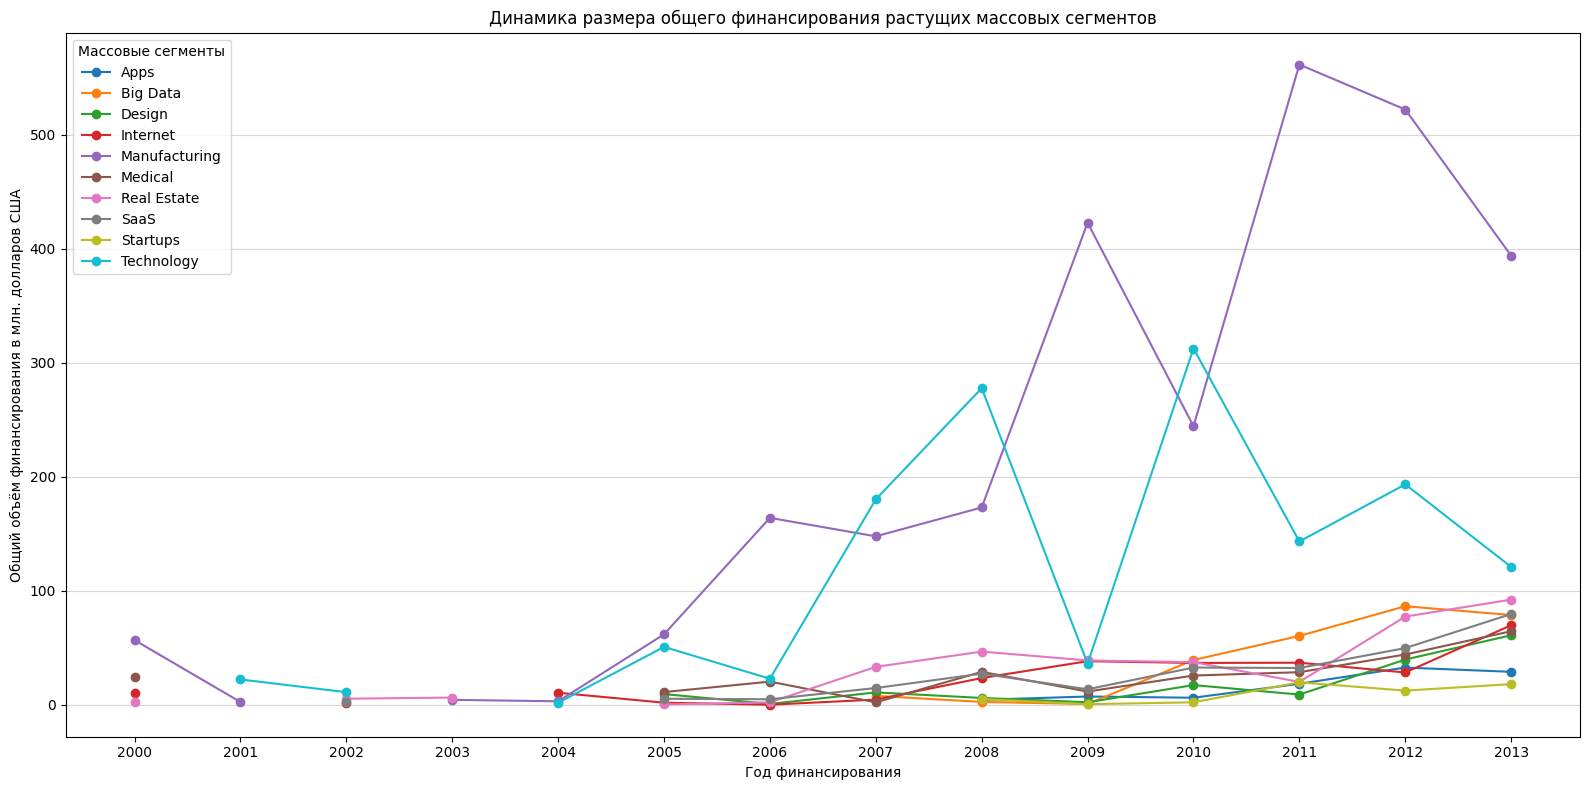

In [44]:
# Отберем данные за годы с достаточной полнотой данных (2014 год исключим):
full_data_years = filtered_pivot_in_mil.loc[2000:2013]

# Построим линейный график на основе наших данных:
filtered_pivot_line = full_data_years.plot(kind = 'line',
                                           title = 'Динамика размера общего финансирования растущих массовых сегментов',
                                           xlabel = 'Год финансирования',
                                           ylabel = 'Общий объём финансирования в млн. долларов США',
                                           marker = 'o',
                                           figsize = (16, 8),
                                           legend = False)

# Оформим легенду:
lines = full_data_years.columns
plt.legend(labels = lines, title = 'Массовые сегменты')

# Сделаем полупрозрачную сетку по оси Y:
plt.grid(axis = 'y', alpha=0.5)

# Выведем наш график:
plt.xticks(full_data_years.index)
plt.tight_layout()
plt.show()

Напомним, что при анализе распределения инвестиционных данных по месяцам за 2014 год мы установили неполноту данных, так как с ноября-декабря начинается обрыв данных. В связи с этим для исключения искажений динамика размера общего финансирования массовых сегментов мы ограничились периодом по 2013 год включительно.

**Итог:** На основе таблицы и графика, мы можем сделать вывод, что значительный рост демонстрирует сегмент `Manufacturing`, который с 2008 по 2009 года показал стремительный рост, а пик по объему финансирования был отмечен в 2011 году на уровне 561,64 миллиона долларов США. Также значительный рост показал сегмент `Technology` с пиковым значением в 312,53 миллионов долларов США в 2010 году. Остальные массовые сегменты (`SaaS`, `Real Estate`, `Medical`, `Apps`, `Big Data`, `Design`, `Internet`) до 2010 года находились внизу графика, но в период 2011–2013 годов стали показывать рост до 100 миллионов долларов США.

[Вернуться к содержанию](#Содержание)

<a id="Годовая-динамика-доли-возвращённых-средств"></a>
### 4.3. Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Наша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. Слишком большие аномальные значения, мы отбросим:

In [45]:
# Сгруппируем данные по годам и посчитаем сумму привлеченного средств по типам финансирования в миллионах долларов:
all_funding_per_year = cb_rounds_50.groupby('funding_year')[funding_types].sum() / 1000000

# Посчитаем долю возвратов по типа финансирования (с защитой от деления на ноль):
returns_share = cb_returns / (all_funding_per_year + 1e-60)

# Отфильтруем данные, используя метод IQR:
Q1 = returns_share.quantile(0.25)
Q3 = returns_share.quantile(0.75)
IQR = Q3 - Q1

# Определим верхнюю и нижнюю границы допустимых значений:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Применим нашу фильтрацию по верхним и нижним границам:
returns_share = returns_share[(returns_share >= lower_bound) & (returns_share <= upper_bound)]

# Выведем нашу таблицу:
returns_share

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,0.996471,0.168922,0.000000,0.697042,0.000000e+00,0.618571,0.266956,0.0,0.000000,2.710694e-01,0.000000,2.591054e-02,0.000000
2001,1.079592,0.107991,0.000000,0.587483,6.666667e-03,0.770258,1.180000,0.0,0.000000,4.600000e+59,0.000000,4.600000e+59,0.000000
2002,0.629707,0.682282,0.000000,0.608878,NaN,0.223388,1.136667,0.0,0.201333,1.133333e+00,0.000000,6.000000e+58,0.000000
2003,0.505276,0.628260,0.000000,0.914397,1.000000e+58,1.038095,0.605720,0.0,NaN,NaN,0.000000,8.000000e+58,0.000000
2004,0.548476,0.837009,0.000000,0.527559,1.000000e+58,0.439698,0.833504,0.0,NaN,NaN,0.000000,5.500000e+59,0.000000
2005,0.674695,0.546586,0.000000,1.071992,NaN,0.344964,0.509894,0.0,0.480000,7.318565e-01,0.000000,5.000000e+58,0.000000
2006,0.925372,0.343678,0.203632,0.759438,1.663181e-01,0.803772,0.674853,0.0,0.935453,NaN,0.000000,1.200000e+59,0.000000
2007,0.366153,0.297243,NaN,0.504971,2.280972e-01,0.602488,0.817837,0.0,0.579056,2.030000e+00,0.000000,5.700000e+59,0.000000
2008,0.297083,0.190873,NaN,0.342060,5.978832e-02,0.927484,0.412476,0.0,0.679925,2.341111e+00,0.000000,4.700000e+59,0.000000


Теперь построим график, на котором отобразим нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`:

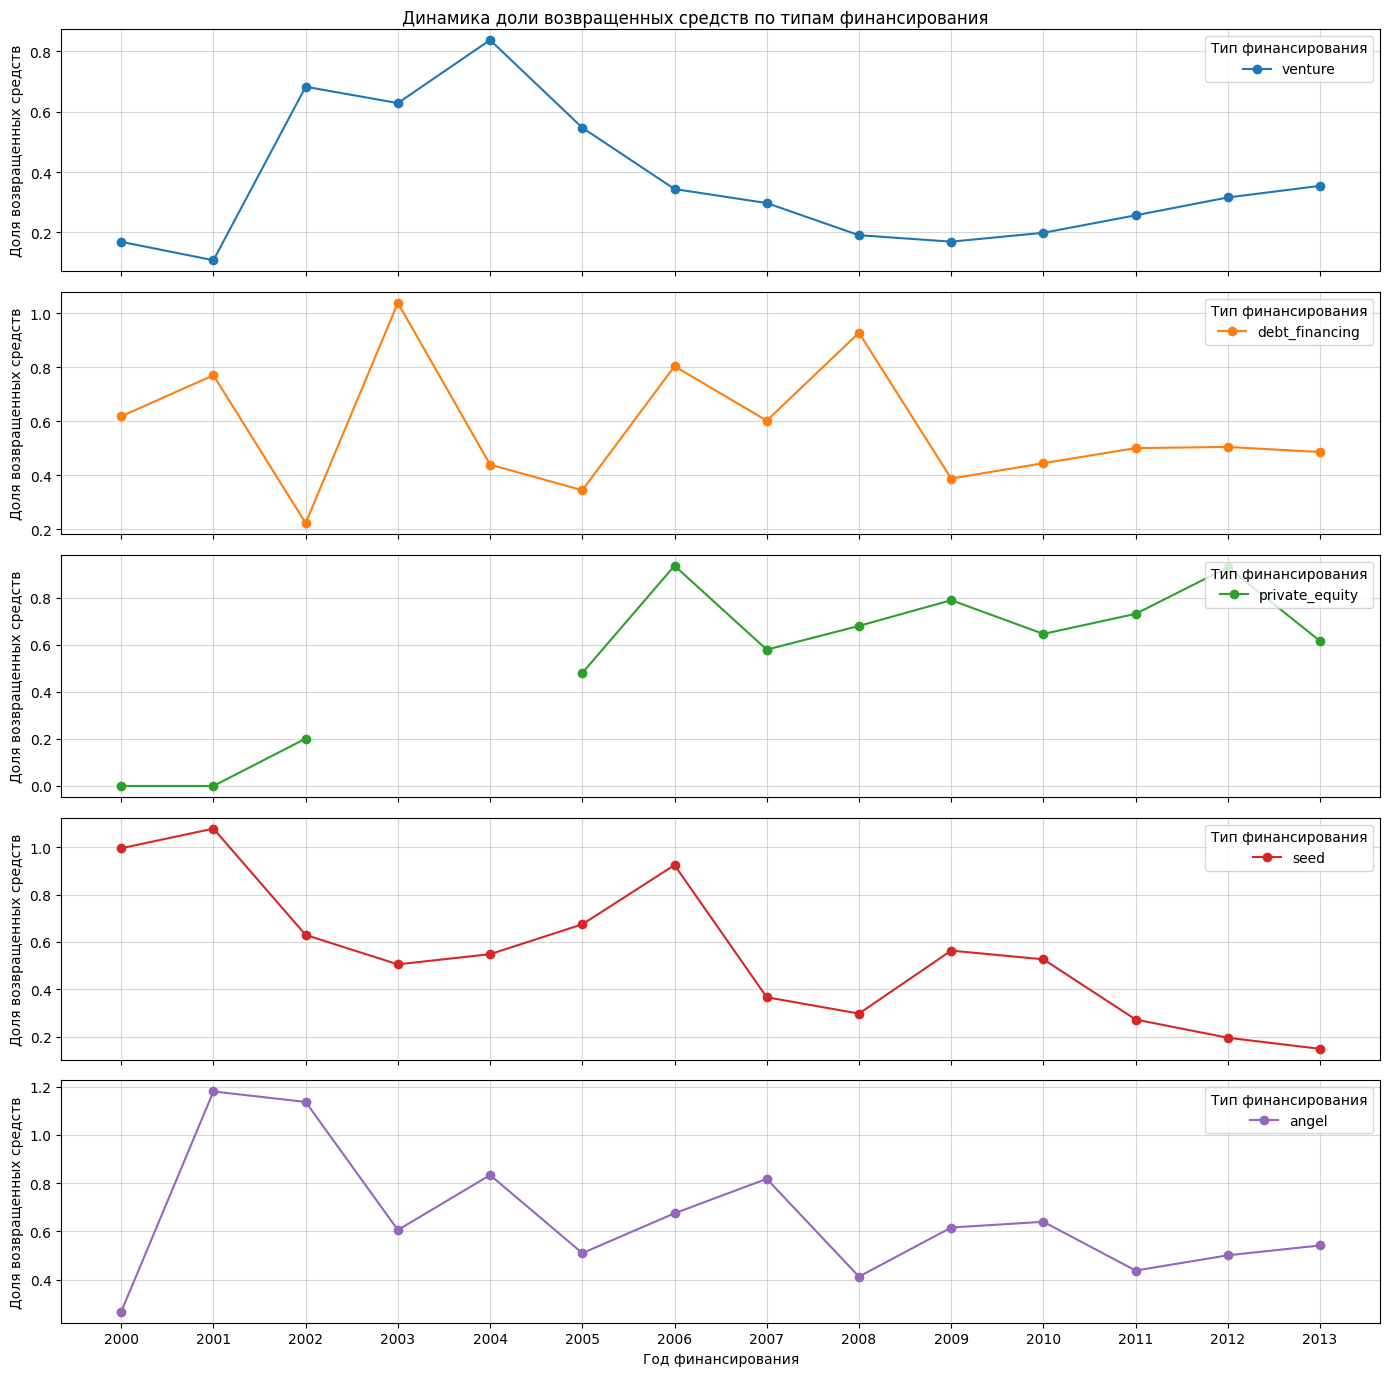

In [46]:
# Сохраним в список нужные нам типы финансирования:
target_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

# Отбираем нужные столбцы и годы с полными данными:
returns_share_data = returns_share.loc[2000:2013, target_types]

# Построим линейный график на основе наших данных:
returns_share_data_line = returns_share_data.plot(kind = 'line',
                                                  title = 'Динамика доли возвращенных средств по типам финансирования',
                                                  xlabel = 'Год финансирования',
                                                  ylabel = 'Доля возвращенных средств',
                                                  marker = 'o',
                                                  subplots = True,
                                                  figsize = (14, 14),
                                                  legend = False)

# Создадим цикл, чтобы настроить график:
for ax, col in zip(returns_share_data_line, returns_share_data.columns):
    
    # Сделаем полупрозрачную сетку по оси Y для каждого подграфика:
    ax.grid(which='both', alpha = 0.5)
    
    # Выведем все года на оси X для каждого подграфика:
    ax.set_xticks(returns_share_data.index)
    
    # Оформим легенду для каждого подграфика:
    ax.legend(labels = [col], 
              loc = 'upper right', 
              title = 'Тип финансирования')

# Выведем наш график:
plt.tight_layout()
plt.show()

**Итог:** На основании построенного графика, мы можем сделать вывод, что наиболее устойчивый  рост показателя наблюдается у венчурного финансирования (`venture`). Достигнув своего минимума в 2009 году на отметке 16,95%, доля росла, увеличившись к 2013 году до 35,42%. В свою очередь такие типы финансирования, как прямые частные вложения (`private_equity`) и долговое финансирование (`debt_financing`) показывают высокую долю возврата, но отмечаются резкими скачками и прерывистостью. Вероятно, из-за разового характера крупных инвестиций.

Также инвестиции на посевной стадии (`seed`) показывают спад возвратов: после роста в 2006 году до 92,54% доля возвратов снижалась до минимума в 14,79% в 2013 году. Инвестиций от бизнес-ангелов (`angel`) после скачков в начале выбранного нами периода стабилизировались в диапазоне от 43,75: до 54,16% в 2011–2013 годах.

Отдельно отметим на графике значения выше 1.0 (100%). У инвестиции на посевной стадии (`seed`) в 2001 году этот показатель составил 107,96%, а у долгового финансирования (`debt_financing`) в 2003 году он достиг 103,81%. Такие значения обусловлены разницей во времени между выделением средств и их возвратом. В эти годы объем привлеченного финансирования был небольшим, тогда как возвратов по прошлым сделкам оказался больше.

[Вернуться к содержанию](#Содержание)

<a id="Результат-анализа-динамики"></a>
### 4.4. Результат анализа динамики

#### Динамика предоставления финансирования по годам

Максимальный типичный размер средств, собранных в рамках одного раунда, был отмечен в 2005 году и равнялся 4,5 миллиона долларов США;
В 2014 году был минимальный (для изучаемого периода) средний объем одного раунда финансирования для каждой компании - 0,56 миллиона долларов США (ровно как и в 2013 году). Что касается количества раундов финансирования в 2014 году, оно равняется 7122. Для сравнения: в 2013 году был отмечен пик количества раундов - 12880, а до этого в 2012 году было 9707 раундов, в 2011 - 7578. Такое "проседание" в 2014 году мы объясняем неполной данных за этот год.

#### Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Мы установили, что значительный рост демонстрирует сегмент `Manufacturing`, который с 2008 по 2009 года показал стремительный рост, а пик по объему финансирования был отмечен в 2011 году на уровне 561,64 миллиона долларов США. Также значительный рост показал сегмент `Technology` с пиковым значением в 312,53 миллионов долларов США в 2010 году. Остальные массовые сегменты (`SaaS`, `Real Estate`, `Medical`, `Apps`, `Big Data`, `Design`, `Internet`, `Startups`) до 2010 года находились ближе к 0, но в период 2011–2013 годов стали показывать рост до 100 миллионов долларов США.

#### Годовая динамика доли возвращённых средств по типам финансирования

Наиболее устойчивый  рост показателя наблюдается у венчурного финансирования (`venture`). Достигнув своего минимума в 2009 году на отметке 16,95%, доля росла, увеличившись к 2013 году до 35,42%. В свою очередь такие типы финансирования, как прямые частные вложения (`private_equity`) и долговое финансирование (`debt_financing`) показывают высокую долю возврата, но отмечаются резкими скачками и прерывистостью. Вероятно, из-за разового характера крупных инвестиций.

Также инвестиции на посевной стадии (`seed`) показывают спад возвратов: после роста в 2006 году до 92,54% доля возвратов снижалась до минимума в 14,79% в 2013 году. Инвестиций от бизнес-ангелов (`angel`) после скачков в начале выбранного нами периода стабилизировались в диапазоне от 43,75: до 54,16% в 2011–2013 годах.

[Вернуться к содержанию](#Содержание)

<a id="Итоговый-вывод-и-рекомендации"></a>
## 5. Итоговый вывод и рекомендации

<a id="Обзор-проделанной-работы-и-выводы"></a>
### 5.1. Обзор проделанной работы и выводы

В рамках проекта мы провели исследование на исторических данных, представленных в двух датасетах `cb_investments` и `cb_returns`. Мы поработали с информацией о компаниях, объёмах и типах привлечённых инвестиций, а также с дополнительной статистикой по возвратам средств.

Прежде, чем приступить к анализу, мы провели предобработку данных. На этом этапе мы привели названия столбцов в порядок, устранили неявные дубликаты (в столбце `market`) и пропуски (например, заполнили текстовые пропуски категорией "не указано", а также удалили строки, которые не несут полезной информации в ключевых показателях финансирования). Преобразовали данные к оптимальным типам: привели в подобающий вид данные, содержащие дату, а также столбец с ключевой информацией о финансировании `funding_total_usd`.

Затем мы провели инжиниринг признаков, в рамках которого раздели компании из датасета на 3 группы по финансированию:
- Большинство компаний (58,9% от общего числа компаний) получают единичное финансирование;
- Долгоживущих компаний также немало - 30,1%.
- Меньше всего компаний в группе со сроком финансирования до года - 11%.

Больше всего инвестиций (61,9%) приходится на компании, где срок финансирования больше года. На единичное финансирование приходится 30,6% инвестиций. Меньше всего инвестиций (7,5%) приходится на группу со сроком финансирования до года.

Также нами были разделены сегменты, в которых работают компании, по принципу массовости использования и получили следующие результаты:
- Массовых сегментов (сегменты, в которых работает больше 120 компаний) - 48;
- Средних (сегменты, в которых работает от 35 до 120 компаний включительно) - 57;
- Нишевых (сегменты, в которых работает до 35 компаний) - 298.

Было принято решение оставить в столбце `market` только массовые сегменты, а для остальных сегментов заменить значения на заглушки — `niche` для нишевых и `mid` для средних, ведь анализировать сотни мелких ниш по отдельности нет практического смысла.

Далее мы поработали с выбросами и установили, что типичный размер финансирования для одной компании находится в диапазоне от 0 до 18 миллионов долларов. Основные инвестиции сосредоточены в границах от 0,5 до 7 миллионов долларов с медианой около 2 миллионов долларов. Все суммы свыше 18 миллионов долларов формируют линию из точек-аномалий. Мы приняли их как аномальные для рассматриваемого периода с помощью метода IQR, создав столбец с бинарным признаком `is_anomaly`.

Также мы определили сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и вывели топ таких сегментов: чаще всего выбивающее финансирование имеют `Real Estate` (17,2%), `Entertainment` (16,67%) и `Consulting` (16,62%). Далее распределены сегменты в топе так: `Search` (16,49%), `Cloud Computing` (16,45%), `Photography` (16,18%), `SaaS` (16,18%), `Technology` (15,97%), `Video` (15,96%). Также в топ вошел нишевый сегмент - 15,9% компаний имеют аномальное финансирование.

В рамках этого же пункта мы установили, что данные за 2014 год неполные, так как в ноябре и декабре обрываются данные, что связано с ошибкой выгрузки. Затем мы исключили из датасета компании, которые имели аномальное финансирование, которое отражено было в нашем столбце `is_anomaly`. Также мы оставили в датасете только те годы, когда в год было 50 и более раундов финансирования и получили отфильтрованный датасет `cb_rounds_50`, который содержит 35588 строк (до фильтрации было 40907).

Мы установили, что абсолютным фаворитом рынка по объему привлеченных средств, по популярности и по возвратам являются венчурные инвестиции (`venture`). Они чаще всего использовались компаниями (18820 раз) и привлекли больше всего денег (129,09 миллиардов долларов США), а также принесли самый большой объём возвратов  — 40,58 миллиардов.

Также мы выделили интересные пункты:
- Часто используется + Привлекает мало денег: Инвестиции на посевной стадии (`seed`), долговое финансирование (`debt_financing`) и инвестиции от бизнес-ангелов (`angel`) используются очень часто (13375, 3265 и 2938 раз соответственно), но характеризуются небольшими средними чеками, поэтому объемы привлеченных средств в рамках их не такие большие (9,43 миллиардов, 8,18 миллиардов и 2,48 миллиарда соответственно);
- Редко используется + Привлекает много денег: Прямые частные вложения (`private_equity`) и финансирование после IPO (`post_ipo_equity`) используются компаниями редко (634 и 164 раз соответственно), однако каждая отдельная сделка приносит огромные суммы (4,84 миллиарда и 1,95 миллиарда).

Затем мы исследовали динамику предоставления финансирования по годам: максимальный типичный размер средств, собранных в рамках одного раунда, был отмечен в 2005 году и равнялся 4,5 миллиона долларов США. В 2014 году был минимальный (для изучаемого периода) средний объем одного раунда финансирования для каждой компании - 0,56 миллиона долларов США (ровно как и в 2013 году). Что касается количества раундов финансирования в 2014 году, оно равняется 7122. Для сравнения: в 2013 году был отмечен пик количества раундов - 12880, а до этого в 2012 году было 9707 раундов, в 2011 - 7578. Такое "проседание" в 2014 году мы объяснили неполной данных за этот год.

Далее мы провели анализ динамики размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов: сегмент `Manufacturing` с 2008 по 2009 года показал стремительный рост, а пик по объему финансирования был отмечен в 2011 году на уровне 561,64 миллиона долларов США. Также значительный рост показал сегмент `Technology` с пиковым значением в 312,53 миллионов долларов США в 2010 году. Остальные массовые сегменты (`SaaS`, `Real Estate`, `Medical`, `Apps`, `Big Data`, `Design`, `Internet`, `Startups`) до 2010 года находились ближе к 0, но в период 2011–2013 годов стали показывать рост до 100 миллионов долларов США.

И наконец, мы рассмотрели годовую динамика доли возвращённых средств по типам финансирования: наиболее устойчивый рост показателя у венчурного финансирования (`venture`). Достигнув своего минимума в 2009 году на отметке 16,95%, доля росла, увеличившись к 2013 году до 35,42%. В свою очередь такие типы финансирования, как прямые частные вложения (`private_equity`) и долговое финансирование (`debt_financing`) показали высокую долю возврата, но отметились резкими скачками и прерывистостью.

Выводы исследования согласуются между собой, так как лидерство венчурных инвестиций по объемам прямо подтверждается его высокой популярностью и растущей доходностью (на основе возвратов). 

[Вернуться к содержанию](#Содержание)

<a id="Рекомендации-инвесторам"></a>
### 5.2. Рекомендации инвесторам

Представим, что на календаре 2015 год. В таких условиях мы бы порекомендовали инвесторам обратить внимание на стабильный вариант - сегмент производства `Manufacturing`. Он постоянно привлекал всё больше и больше средств (с 2008 по 2009 года показал стремительный рост, а пик по объему финансирования был отмечен в 2011 году на уровне 561,64 миллиона долларов США), что характеризует её как отрасль с крупными чеками. Она является стабильной и предсказуемой. По тем же причинам стоит обратить внимание и на `Technology` (пиковое значение в 312,53 миллионов долларов США в 2010 году).

Однако основной капитал стоит диверсифицировать, вложив его в такие сегменты, как `SaaS` (программное обеспечение как услуга), `Real Estate` (недвижимость), `Medical` (медицина), `Apps` (приложения), `Big Data` (сбор, хранение и обработка данных), `Design` (дизайн), `Internet` (интернет). До 2010 года они были на околонулевом уровне, однако в период 2011–2013 годов стали показывать рост до 100 миллионов долларов США, что указывает на рост их актуальности и востребованности.

Что касается оптимального типа финансирования: как основной инструмент стоит использовать венчурные инвестиции (они являются абсолютным фаворитом рынка по объему привлеченных средств, по популярности и по возвратам). Данный инструмент показал наиболее устойчивый рост по возвратам. Также стоит обратить внимание на прямые частные вложения, которые показывают высокую долю возвратов. Это оптимальный инструмент для входа в уже зрелые проекты.

Наконец, рекомендуем входить в проекты с долгосрочным финансированием, ведь больше всего инвестиций (61,9%) приходится на компании, где срок финансирования больше года.

[Вернуться к содержанию](#Содержание)